# PIDM-DP: Physics-Informed Diffusion for Chaotic Systems

**Dormand–Prince edition · Lorenz-63 · sparse-observation state & parameter reconstruction**

*Author: Shailendra Dabral*

A 1D temporal U-Net diffusion model is trained on Lorenz-63 trajectories (state **and** parameters σ, ρ, β as channels). At inference only **10 %** of the time steps are observed (with noise); the trajectory and parameters are recovered via guided reverse diffusion, where the guidance combines a data-fidelity term with a differentiable **Dormand–Prince RK45** physics residual.

**Contents:** setup (§1–15) → Phase 1 training → Phases 2–3 ID/OOD evaluation → Phase 4 capacity ablation → Phase 5 physics-weight sweep → Phase 6–7 robustness → Phases 8–9 figures.

> **Runtime:** full pipeline was run on a Kaggle Tesla T4. Each phase caches results in `models/lorenz63/*.pkl`; delete them to recompute. Expect several GPU-hours from scratch.

## 1. Environment & dependencies

Imports, device detection (Kaggle-aware paths) and publication plot styling.

In [1]:
# CELL 2: Environment & Dependencies
import os, sys, math, time, random, warnings, pickle, platform
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.stats import wilcoxon
import scipy.stats as st
from sklearn.metrics import mean_squared_error

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# Detect Kaggle environment
IS_KAGGLE = os.path.exists("/kaggle/working")
BASE_DIR = "/kaggle/working" if IS_KAGGLE else "."

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"  PIDM-DP V9.1 · LORENZ-63 REVISED JOURNAL PIPELINE")
print(f"  Environment   : {'Kaggle (Cloud GPU)' if IS_KAGGLE else 'Local / Workstation'}")
print(f"  Base Directory: {BASE_DIR}")
print(f"  PyTorch       : {torch.__version__} | Device: {DEVICE}", end="")
if torch.cuda.is_available():
    print(f" [{torch.cuda.get_device_name(0)}] (VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
else:
    print(" [CPU Mode]")
print("=" * 70)

# Unified publication styling
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Times New Roman"],
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.5,
})

PALETTE = {
    "gt":        "#1A1A2E",
    "pidm":      "#6C3483",
    "pidm_ai":   "#C0392B",
    "enkf":      "#E67E22",
    "micro":     "#2980B9",
    "bg":        "#F8F9FA",
}


  PIDM-DP V9.1 · LORENZ-63 REVISED JOURNAL PIPELINE
  Environment   : Kaggle (Cloud GPU)
  Base Directory: /kaggle/working
  PyTorch       : 2.8.0+cu126 | Device: cuda [Tesla T4] (VRAM: 15.6 GB)


## 2. Configuration

Single source of truth for system ranges, integrator, diffusion, training, guidance and EnKF settings.

In [3]:
# CELL 3: Configuration Dictionary
CONFIG = {
    "paths": {
        "results_dir":  os.path.join(BASE_DIR, "results", "lorenz63"),
        "checkpoints":  os.path.join(BASE_DIR, "models", "lorenz63"),
        "figures":      os.path.join(BASE_DIR, "figures", "lorenz63"),
    },
    "lorenz": {
        "state_dim": 3,
        "param_dim": 3,
        "ranges":     [(8.0, 12.0), (20.0, 35.0), (2.0, 4.0)],     # ID: sigma, rho, beta
        "ood_ranges": [(5.0,  8.0), (15.0, 20.0), (1.5, 2.0)],     # OOD: pre-chaotic boundary
        "param_names": [r"$\sigma$", r"$\rho$", r"$\beta$"],
        "param_keys":  ["sigma", "rho", "beta"],
        "lyap_ref": 0.906,
        "ic_range": [(-15, 15), (-15, 15), (10, 35)],
        "lyap_params": {"emb_dim": 3, "lag": 2, "min_tsep": 25, "tlen": 75, "len": 8000},
    },
    "integrator_settings": {
        "lorenz": {"method": "DOP853", "rtol": 1e-8, "atol": 1e-10, "max_step": 0.1},
    },
    "data": {
        "n_samples":  1000,
        "n_points":   1000,
        "dt":         0.05,
        "obs_ratio":  0.10,
        "val_frac":   0.10,
        "transient":  700,
        "lyap_len":   5000,
        "obs_noise":  0.05,
    },
    "diffusion": {
        "T":          1000,
        "beta_start": 1e-4,
        "beta_end":   0.02,
    },
    "training": {
        "epochs":       80,
        "batch_size":   32,
        "lr":           2e-4,
        "lr_min":       1e-6,
        "weight_decay": 1e-5,
        "grad_clip":    1.0,
        "patience":     15,
        "seed":         42,
    },
    # Model capacity scales
    "model_scales": {
        "full":  {"base_ch": 64, "time_dim": 128, "use_attn": True},   # ~2.93M parameters (original)
        "micro": {"base_ch": 8,  "time_dim": 32, "use_attn": False},  # ~53k parameters (O(10^4))
    },
    # Guidance parameters
    "guidance": {
        "w_data":       150.0,
        "w_phy":          2.0,
        "grad_clip":     0.15,
        "w_phy_override": {"lorenz": 2.0},
    },
    "enkf": {
        "n_ensemble":       50,
        "state_init_noise":  2.0,
        "param_noise_frac":  0.3,
        "pf_regularisation": 1e-4,
        "inflation":        1.02,
    },
    "noise_levels":     [0.0, 0.05, 0.15],
    "sparsity_levels":  [0.02, 0.05, 0.10],
    "lambda_phy_sweep": [0.0, 0.5, 1.0, 2.0, 5.0],
}

_SYSTEMS = ["lorenz"]
SYSTEM_LABEL = "Lorenz-63"

for p in CONFIG["paths"].values():
    os.makedirs(p, exist_ok=True)

print("  Configuration loaded successfully.")
print(f"  Results directory     : {CONFIG['paths']['results_dir']}")
print(f"  Checkpoints directory : {CONFIG['paths']['checkpoints']}")
print(f"  Figures directory     : {CONFIG['paths']['figures']}")


  Configuration loaded successfully.
  Results directory     : /kaggle/working/results/lorenz63
  Checkpoints directory : /kaggle/working/models/lorenz63
  Figures directory     : /kaggle/working/figures/lorenz63


## 3. Reproducibility & checkpointing

Seeding plus a resume system so long phases can be skipped on re-run.

In [4]:
# CELL 4: Checkpoint / Resume System
def set_seed(s: int) -> None:
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark     = False

GLOBAL_SEED = CONFIG["training"]["seed"]
set_seed(GLOBAL_SEED)

CKPT_DIR = Path(CONFIG["paths"]["checkpoints"])

def _ckpt_path(name: str) -> Path:
    return CKPT_DIR / f"checkpoint_{name}.pkl"

def save_checkpoint(name: str, data: dict) -> None:
    path = _ckpt_path(name)
    torch.save(data, path)
    print(f"  [OK] Checkpoint saved  --> {path.name} ({path.stat().st_size / 1024:.1f} KB)")

def load_checkpoint(name: str):
    path = _ckpt_path(name)
    if path.exists():
        try:
            data = torch.load(path, map_location=DEVICE, weights_only=False)
            print(f"  [RESUME] Checkpoint loaded <-- {path.name}")
            return data
        except Exception as e:
            print(f"  [WARN] Corrupt checkpoint {path.name} ({e}) -- will recompute.")
            return None
    return None

def checkpoint_exists(name: str) -> bool:
    return _ckpt_path(name).exists()

print(f"  Global Seed: {GLOBAL_SEED} | Checkpoint Directory: {CKPT_DIR}")


  Global Seed: 42 | Checkpoint Directory: /kaggle/working/models/lorenz63


## 4. Physics: ground-truth ODE integration

Lorenz-63 right-hand side with an 8th-order DOP853 integrator (LSODA fallback) for data generation.

In [5]:
# CELL 5: ODE Physics Functions (DOP853 Integrator with LSODA Fallback)
def lorenz_sys(t, y, sigma, rho, beta):
    x, yy, z = y
    return [sigma * (yy - x), x * (rho - z) - yy, x * yy - beta * z]

_SYS_FN_MAP = {"lorenz": lorenz_sys}

def get_sys_fn(sys_type: str):
    if sys_type not in _SYS_FN_MAP:
        raise ValueError(f"Unknown system: {sys_type}")
    return _SYS_FN_MAP[sys_type]

def integrate_trajectory(fn, y0, t_span, t_eval, params, sys_type="lorenz"):
    s = CONFIG["integrator_settings"].get(sys_type, {"method": "DOP853", "rtol": 1e-8, "atol": 1e-10, "max_step": 0.1})
    method, rtol, atol, max_step = s["method"], s["rtol"], s["atol"], s["max_step"]

    bound = 500.0
    def blowup_event(t, y, *args):
        return bound - np.max(np.abs(y))
    blowup_event.terminal = True
    blowup_event.direction = -1

    def _pad_failed(sol_y):
        pad_len = len(t_eval) - sol_y.shape[1]
        if pad_len > 0:
            return np.hstack([sol_y, np.full((sol_y.shape[0], pad_len), np.nan)])
        return sol_y

    try:
        sol = solve_ivp(
            lambda t, y: fn(t, y, *params),
            t_span, y0, method=method, t_eval=t_eval,
            rtol=rtol, atol=atol, max_step=max_step, events=[blowup_event]
        )
        if sol.success:
            return sol.y.T
        elif sol.status == 1:
            return _pad_failed(sol.y).T
    except Exception:
        pass

    try:
        sol = solve_ivp(
            lambda t, y: fn(t, y, *params),
            t_span, y0, method="LSODA", t_eval=t_eval,
            rtol=1e-4, atol=1e-6, events=[blowup_event]
        )
        if sol.success or sol.status == 1:
            return _pad_failed(sol.y).T
    except Exception:
        pass

    return None

print("  ODE integrator ready: 8th-order DOP853 with LSODA fallback.")


  ODE integrator ready: 8th-order DOP853 with LSODA fallback.


## 5. Differentiable Dormand–Prince RK45 step

A PyTorch DP-RK45 step used inside the guidance loss, checked against a NumPy reference.

In [6]:
# CELL 6: Differentiable PyTorch DP-RK45 Integrator
def lorenz_torch(s, p):
    x, y, z = s[:, 0:1], s[:, 1:2], s[:, 2:3]
    sigma, rho, beta = p[:, 0:1], p[:, 1:2], p[:, 2:3]
    return torch.cat([sigma * (y - x), x * (rho - z) - y, x * y - beta * z], dim=1)

_TORCH_FN_MAP = {"lorenz": lorenz_torch}

def get_torch_fn(sys_type: str):
    return _TORCH_FN_MAP[sys_type]

def dp_rk45_step(fn, s, p, dt):
    dt_t = dt if isinstance(dt, torch.Tensor) else torch.tensor(dt, dtype=s.dtype, device=s.device)
    k1 = fn(s, p)
    k2 = fn(s + dt_t * (0.2) * k1, p)
    k3 = fn(s + dt_t * (0.075) * k1 + dt_t * (0.225) * k2, p)
    k4 = fn(s + dt_t * (44.0 / 45.0) * k1 - dt_t * (56.0 / 15.0) * k2 + dt_t * (32.0 / 9.0) * k3, p)
    k5 = fn(s + dt_t * (19372.0 / 6561.0) * k1 - dt_t * (25360.0 / 2187.0) * k2 + dt_t * (64448.0 / 6561.0) * k3 - dt_t * (212.0 / 729.0) * k4, p)
    k6 = fn(s + dt_t * (9017.0 / 3168.0) * k1 - dt_t * (355.0 / 33.0) * k2 + dt_t * (46732.0 / 5247.0) * k3 + dt_t * (49.0 / 176.0) * k4 - dt_t * (5103.0 / 18656.0) * k5, p)
    return s + dt_t * (35.0 / 384.0 * k1 + 500.0 / 1113.0 * k3 + 125.0 / 192.0 * k4 - 2187.0 / 6784.0 * k5 + 11.0 / 84.0 * k6)

# Validation
_dt = 0.01
ic = np.array([1.0, 1.0, 1.0])
pv = [10.0, 28.0, 8.0 / 3.0]
s_t = torch.tensor(ic, dtype=torch.float64).reshape(1, 3, 1).to(DEVICE)
p_t = torch.tensor(pv, dtype=torch.float64).reshape(1, 3, 1).to(DEVICE)
with torch.no_grad():
    step_t = dp_rk45_step(get_torch_fn("lorenz"), s_t, p_t, _dt).squeeze().cpu().numpy()

def numpy_dp_rk45_step(fn, s, p, dt):
    def _f(y, p_args): return np.array(fn(0, y, *p_args), dtype=np.float64)
    k1 = _f(s, p)
    k2 = _f(s + dt * (0.2) * k1, p)
    k3 = _f(s + dt * (0.075) * k1 + dt * (0.225) * k2, p)
    k4 = _f(s + dt * (44/45) * k1 - dt * (56/15) * k2 + dt * (32/9) * k3, p)
    k5 = _f(s + dt * (19372/6561) * k1 - dt * (25360/2187) * k2 + dt * (64448/6561) * k3 - dt * (212/729) * k4, p)
    k6 = _f(s + dt * (9017/3168) * k1 - dt * (355/33) * k2 + dt * (46732/5247) * k3 + dt * (49/176) * k4 - dt * (5103/18656) * k5, p)
    return s + dt * (35/384 * k1 + 500/1113 * k3 + 125/192 * k4 - 2187/6784 * k5 + 11/84 * k6)

step_np = numpy_dp_rk45_step(get_sys_fn("lorenz"), ic, pv, _dt)
diff = np.max(np.abs(step_np - step_t))
print(f"  DP-RK45 Bit-Consistency check: max diff = {diff:.2e} -> {'PASSED' if diff < 1e-13 else 'FAILED'}")


  DP-RK45 Bit-Consistency check: max diff = 0.00e+00 -> PASSED


## 6. Dataset generator

Samples (σ, ρ, β) and initial conditions, integrates, discards the transient. OOD ranges sit near the pre-chaotic boundary.

In [7]:
# CELL 7: Chaotic Dataset Generator
def generate_chaotic_dataset(sys_type="lorenz", n_samples=1000, n_points=1000, dt=0.05,
                             transient=700, ood=False, seed=None):
    rng = np.random.RandomState(seed)
    cfg = CONFIG[sys_type]
    fn = get_sys_fn(sys_type)
    param_ranges = cfg["ood_ranges"] if ood else cfg["ranges"]
    state_dim = cfg["state_dim"]
    ic_range = cfg.get("ic_range", [(-15, 15), (-15, 15), (10, 35)])
    t_total_end = (n_points + transient) * dt
    t_eval_full = np.linspace(0, t_total_end, n_points + transient)

    data = []
    pbar = tqdm(total=n_samples, desc=f"  DOP853 {sys_type.upper()}{'[OOD]' if ood else '[ID]'}", leave=False)

    while len(data) < n_samples:
        p_vals = [rng.uniform(*param_ranges[i]) for i in range(cfg["param_dim"])]
        x0 = [rng.uniform(r[0], r[1]) for r in ic_range]
        traj = integrate_trajectory(fn, x0, (0, t_total_end), t_eval_full, p_vals, sys_type=sys_type)

        if traj is not None and np.isfinite(traj).all() and np.abs(traj[transient:]).max() < 500.0:
            traj_seg = traj[transient:]
            p_arr = np.stack([np.full(n_points, p) for p in p_vals], axis=0)
            data.append(np.vstack([traj_seg.T, p_arr]))
            pbar.update(1)

    pbar.close()
    return np.array(data, dtype=np.float32)

print("  Dataset generator defined.")


  Dataset generator defined.


## 7. Preprocessing & observation masking

Min–max normalisation, random sparse masks and observation noise.

In [8]:
# CELL 8: Preprocessing & Masking
class DataPreprocessor:
    def __init__(self, data_np: np.ndarray):
        self.min_v = torch.tensor(data_np.min(axis=(0, 2), keepdims=True), dtype=torch.float32).to(DEVICE)
        self.max_v = torch.tensor(data_np.max(axis=(0, 2), keepdims=True), dtype=torch.float32).to(DEVICE)

    def normalize(self, x: torch.Tensor) -> torch.Tensor:
        return 2.0 * (x.to(DEVICE) - self.min_v) / (self.max_v - self.min_v + 1e-8) - 1.0

    def denormalize(self, xn: torch.Tensor) -> torch.Tensor:
        return (xn.to(DEVICE) + 1.0) / 2.0 * (self.max_v - self.min_v) + self.min_v

    def to_device(self, device):
        self.min_v = self.min_v.to(device)
        self.max_v = self.max_v.to(device)
        return self

def make_random_mask(shape, obs_ratio, device, state_dim, rng=None):
    B, C, L = shape
    n_obs = max(1, int(L * obs_ratio))
    _rng = rng if rng is not None else np.random
    obs_idx = np.sort(_rng.choice(L, n_obs, replace=False))
    mask = torch.zeros(shape, device=device)
    mask[:, :state_dim, obs_idx] = 1.0
    return mask, obs_idx

def add_observation_noise(x_norm, mask, noise_std):
    x_noisy = torch.zeros_like(x_norm)
    obs = mask > 0
    noise = torch.randn(obs.sum().item(), device=x_norm.device) * noise_std
    x_noisy[obs] = x_norm[obs] + noise
    return x_noisy

print("  Preprocessing tools ready.")


  Preprocessing tools ready.


## 8. Guidance engine

Data-fidelity guidance plus a time-scheduled DP-RK45 physics residual. Setting `force_pure_ai=True` gives the *data-only* baseline (λ_phy = 0).

In [9]:
# CELL 9: Guidance Engine
def stable_guidance(x_t, t, x_obs_noisy, mask, model, diff, prep, sys_type, force_pure_ai=False):
    """
    Guidance Engine with Data Fidelity and Scheduled DP-RK45 Physics.
    When force_pure_ai=True or w_phy=0, it executes TRUE Pure AI (Data-Guided Diffusion):
    It applies grad(w_data * L_data) alone to strictly anchor observed points.
    When w_phy > 0, it applies joint Data + Scheduled DP-RK45 Physics guidance.
    """
    gcfg = CONFIG["guidance"]
    base_w_phy = 0.0 if force_pure_ai else gcfg["w_phy_override"].get(sys_type, gcfg.get("w_phy", 2.0))

    t_idx  = t[0].item() if t.dim() > 0 else t.item()
    t_frac = 1.0 - (t_idx / float(diff.T))
    w_phy  = base_w_phy * t_frac

    xi = x_t.detach().requires_grad_(True)

    with torch.enable_grad():
        eps = model(xi, t)
        ab  = diff.alpha_bars[t.long()].view(-1, 1, 1)
        x0h = (xi - torch.sqrt(1.0 - ab) * eps) / torch.sqrt(ab)

        # Data fidelity term
        obs_mask = mask > 0
        l_data = F.mse_loss(x0h[obs_mask], x_obs_noisy[obs_mask])

        if w_phy > 0:
            x0p = prep.denormalize(x0h)
            fn  = get_torch_fn(sys_type)
            dt  = CONFIG["data"]["dt"]
            s_dim = CONFIG[sys_type]["state_dim"]

            s = x0p[:, :s_dim, :-1]
            p = x0p[:, s_dim:, :].mean(dim=2, keepdim=True)

            s_next_pred   = dp_rk45_step(fn, s, p, dt)
            s_next_actual = x0p[:, :s_dim, 1:]
            l_phy = torch.log1p(F.mse_loss(s_next_pred, s_next_actual))
            total_loss = (gcfg["w_data"] * l_data) + (w_phy * l_phy)
        else:
            total_loss = gcfg["w_data"] * l_data

        grad = torch.autograd.grad(total_loss, xi)[0]

    gnorm = torch.norm(grad) + 1e-8
    clip  = torch.clamp(gnorm, max=gcfg["grad_clip"])
    return -(grad / gnorm) * clip

print("  Guidance engine ready.")


  Guidance engine ready.


## 9. Temporal U-Net

1D residual U-Net with optional self-attention bottleneck, at *full* (~2.93M) and *micro* (~53k) scale.

In [10]:
# CELL 10: Scalable Temporal U-Net
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half  = self.dim // 2
        denom = max(half - 1, 1)
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / denom)
        args  = t[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)

class ResBlock1d(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        g = min(8, out_ch)
        self.conv1     = nn.Conv1d(in_ch, out_ch, 3, padding=1)
        self.conv2     = nn.Conv1d(out_ch, out_ch, 3, padding=1)
        self.norm1     = nn.GroupNorm(g, out_ch)
        self.norm2     = nn.GroupNorm(g, out_ch)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.skip      = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = F.silu(self.norm1(self.conv1(x))) + self.time_proj(t_emb).unsqueeze(-1)
        return F.silu(self.norm2(self.conv2(h))) + self.skip(x)

class SelfAttention1d(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        nh = min(num_heads, max(1, channels // 8))
        self.attn = nn.MultiheadAttention(channels, nh, batch_first=True)
        self.norm = nn.LayerNorm(channels)

    def forward(self, x):
        h = x.permute(0, 2, 1)
        h_n = self.norm(h)
        attn_o, _ = self.attn(h_n, h_n, h_n)
        return (h + attn_o).permute(0, 2, 1)

class TemporalUNet(nn.Module):
    """
    Scalable 1D Temporal U-Net for Diffusion Denoising.
    Allows testing full-scale (~3M params) vs compact O(10^4) models.
    """
    def __init__(self, channels=6, time_dim=128, base_ch=64, use_attention=True):
        super().__init__()
        c1, c2, c3 = base_ch, base_ch * 2, base_ch * 4
        self.time_mlp = nn.Sequential(
            SinusoidalEmbedding(time_dim),
            nn.Linear(time_dim, time_dim * 4), nn.SiLU(),
            nn.Linear(time_dim * 4, time_dim),
        )
        self.enc1a = ResBlock1d(channels, c1, time_dim)
        self.enc1b = ResBlock1d(c1, c1, time_dim)
        self.enc2a = ResBlock1d(c1, c2, time_dim)
        self.enc2b = ResBlock1d(c2, c2, time_dim)
        self.enc3a = ResBlock1d(c2, c3, time_dim)
        self.enc3b = ResBlock1d(c3, c3, time_dim)
        self.pool  = nn.AvgPool1d(2)
        self.mid_a = ResBlock1d(c3, c3, time_dim)
        self.attn  = SelfAttention1d(c3) if use_attention else nn.Identity()
        self.mid_b = ResBlock1d(c3, c3, time_dim)
        self.dec3a = ResBlock1d(c3 + c3, c2, time_dim)
        self.dec3b = ResBlock1d(c2, c2, time_dim)
        self.dec2a = ResBlock1d(c2 + c2, c1, time_dim)
        self.dec2b = ResBlock1d(c1, c1, time_dim)
        self.dec1a = ResBlock1d(c1 + c1, c1, time_dim)
        self.out   = nn.Conv1d(c1, channels, 1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        e1 = self.enc1b(self.enc1a(x, t_emb), t_emb)
        e2 = self.enc2b(self.enc2a(self.pool(e1), t_emb), t_emb)
        e3 = self.enc3b(self.enc3a(self.pool(e2), t_emb), t_emb)
        m  = self.mid_b(self.attn(self.mid_a(self.pool(e3), t_emb)), t_emb)
        d3 = self.dec3b(self.dec3a(torch.cat([F.interpolate(m, e3.shape[-1], mode="linear", align_corners=False), e3], 1), t_emb), t_emb)
        d2 = self.dec2b(self.dec2a(torch.cat([F.interpolate(d3, e2.shape[-1], mode="linear", align_corners=False), e2], 1), t_emb), t_emb)
        d1 = self.dec1a(torch.cat([F.interpolate(d2, e1.shape[-1], mode="linear", align_corners=False), e1], 1), t_emb)
        return self.out(d1)

    def count_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

print("  Model Scale Configurations:")
for scale, scfg in CONFIG["model_scales"].items():
    _m = TemporalUNet(channels=6, time_dim=scfg["time_dim"], base_ch=scfg["base_ch"], use_attention=scfg["use_attn"]).to(DEVICE)
    print(f"    - {scale.upper():<8}: base_ch={scfg['base_ch']:<2} | params = {_m.count_params():,}")
    del _m


  Model Scale Configurations :
    - FULL    : base_ch=64 | params = 2,930,054
    - MICRO   : base_ch=8  | params = 53,382


## 10. DDPM scheduler & guided sampler

Linear-β DDPM with reverse sampling that applies guidance after each step.

In [12]:
# CELL 11: DDPM Diffusion Scheduler & Guided Sampler
class Diffusion:
    def __init__(self, T, b_start, b_end):
        self.T          = T
        self.betas      = torch.linspace(b_start, b_end, T, device=DEVICE)
        self.alphas     = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

    def to_device(self, device):
        self.betas      = self.betas.to(device)
        self.alphas     = self.alphas.to(device)
        self.alpha_bars = self.alpha_bars.to(device)
        return self

    def q_sample(self, x0, t, noise):
        ab = self.alpha_bars[t][:, None, None]
        return torch.sqrt(ab) * x0 + torch.sqrt(1.0 - ab) * noise

def guided_reconstruction(model, diff, prep, x_true_norm, mask, guidance_fn=None, show_progress=False):
    model.eval()
    B = x_true_norm.shape[0]
    x = torch.randn_like(x_true_norm).to(DEVICE)

    steps = tqdm(reversed(range(diff.T)), total=diff.T, disable=not show_progress, leave=False, desc="  Reverse diffusion")
    for t_idx in steps:
        t    = torch.full((B,), t_idx, device=DEVICE, dtype=torch.float)
        beta = diff.betas[t_idx]
        ab   = diff.alpha_bars[t_idx]
        ab_p = diff.alpha_bars[t_idx - 1] if t_idx > 0 else torch.tensor(1.0, device=DEVICE)

        with torch.no_grad():
            ep  = model(x, t)
            x0h = torch.clamp((x - torch.sqrt(1.0 - ab) * ep) / torch.sqrt(ab), -3.0, 3.0)
            mean = (torch.sqrt(ab_p) * beta / (1.0 - ab)) * x0h + (torch.sqrt(diff.alphas[t_idx]) * (1.0 - ab_p) / (1.0 - ab)) * x
            var   = beta * (1.0 - ab_p) / (1.0 - ab)
            noise = torch.randn_like(x) if t_idx > 0 else torch.zeros_like(x)
            x     = mean + torch.sqrt(var) * noise

        if guidance_fn is not None:
            try:
                g = guidance_fn(x, t)
                if torch.isfinite(g).all():
                    x = (x + g).detach()
            except Exception:
                pass

    return x

print("  Diffusion Sampler ready.")


  Diffusion Sampler ready.


## 11. EnKF baseline

Joint state–parameter Ensemble Kalman Filter (RK4 propagation). Note: it is initialised from the true initial state, so it is an *oracle-style* baseline.

In [13]:
# CELL 12: Ensemble Kalman Filter (EnKF) Oracle Baseline
def run_enkf(sys_name, x_gt_phys, obs_idx, noise_std):
    ekf          = CONFIG["enkf"]
    n_ens        = ekf["n_ensemble"]
    n_points     = x_gt_phys.shape[1]
    dt           = CONFIG["data"]["dt"]
    fn           = get_sys_fn(sys_name)
    s_dim        = CONFIG[sys_name]["state_dim"]
    p_dim        = CONFIG[sys_name]["param_dim"]
    tot_dim      = s_dim + p_dim
    param_ranges = CONFIG[sys_name]["ranges"]

    obs_noise_std = max(noise_std * float(np.std(x_gt_phys[:s_dim])), 1e-6)
    x_obs   = x_gt_phys[:s_dim, obs_idx] + np.random.normal(0, obs_noise_std, (s_dim, len(obs_idx)))
    obs_set = set(obs_idx.tolist())

    noise_p = np.array([ekf["param_noise_frac"] * (r[1] - r[0]) for r in param_ranges])
    ens     = np.zeros((tot_dim, n_ens))
    ens[:s_dim, :] = (x_gt_phys[:s_dim, 0:1] + np.random.normal(0, ekf["state_init_noise"], (s_dim, n_ens)))
    prior_p = np.array([(r[0] + r[1]) / 2.0 for r in param_ranges])
    ens[s_dim:, :] = prior_p[:, None] + np.random.normal(0, noise_p[:, None], (p_dim, n_ens))

    H   = np.zeros((s_dim, tot_dim))
    H[:s_dim, :s_dim] = np.eye(s_dim)
    R   = np.eye(s_dim) * (obs_noise_std ** 2)
    REG = np.eye(tot_dim) * ekf["pf_regularisation"]
    INFLATION = ekf["inflation"]

    result = np.zeros((tot_dim, n_points))
    _clip_bound = 200.0

    def _safe_eval(s_in, p_in):
        try:
            out = np.array(fn(None, s_in.tolist(), *p_in), dtype=float)
            return np.clip(out, -1e6, 1e6)
        except Exception:
            return np.full_like(s_in, np.nan)

    def rk4_step_np(s, p):
        s = np.clip(s, -_clip_bound, _clip_bound)
        k1 = _safe_eval(s, p)
        k2 = _safe_eval(np.clip(s + 0.5 * dt * k1, -_clip_bound, _clip_bound), p)
        k3 = _safe_eval(np.clip(s + 0.5 * dt * k2, -_clip_bound, _clip_bound), p)
        k4 = _safe_eval(np.clip(s + dt * k3, -_clip_bound, _clip_bound), p)
        if not (np.isfinite(k1).all() and np.isfinite(k2).all() and np.isfinite(k3).all() and np.isfinite(k4).all()):
            return np.full_like(s, np.nan)
        return np.clip(s + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4), -_clip_bound, _clip_bound)

    for step in range(n_points):
        for j in range(n_ens):
            new_s = rk4_step_np(ens[:s_dim, j], ens[s_dim:, j])
            if np.isfinite(new_s).all():
                ens[:s_dim, j] = new_s
            else:
                good = [k for k in range(n_ens) if np.isfinite(ens[:s_dim, k]).all()]
                if good:
                    ens[:s_dim, j] = np.mean(ens[:s_dim, good], axis=1) + np.random.normal(0, 0.1, s_dim)

        if step in obs_set:
            mean_ens = np.mean(ens, axis=1, keepdims=True)
            ens = mean_ens + INFLATION * (ens - mean_ens)
            pos = int(np.where(obs_idx == step)[0][0])
            Pf  = np.cov(ens) + REG
            S   = H @ Pf @ H.T + R
            try:
                K = Pf @ H.T @ np.linalg.solve(S, np.eye(s_dim))
            except np.linalg.LinAlgError:
                K = Pf @ H.T @ np.linalg.pinv(S)

            for j in range(n_ens):
                inno = (x_obs[:, pos] + np.random.normal(0, obs_noise_std, s_dim) - H @ ens[:, j])
                update = K @ inno
                if np.isfinite(update).all():
                    ens[:, j] += update

        result[:, step] = np.mean(ens, axis=1)

    return np.nan_to_num(result, nan=999.0, posinf=999.0, neginf=-999.0)

print("  EnKF Oracle Baseline ready.")


  EnKF Oracle Baseline ready.


## 12. Metrics

Trajectory RMSE; parameter MAE / range-normalised error (NAE) / MAPE; Rosenstein Lyapunov estimator.

In [14]:
# CELL 13: Multi-Metric Suite
def trajectory_rmse(gt, pred):
    gt_c   = np.clip(np.nan_to_num(gt, nan=999.0, posinf=999.0, neginf=-999.0), -1e6, 1e6)
    pred_c = np.clip(np.nan_to_num(pred, nan=999.0, posinf=999.0, neginf=-999.0), -1e6, 1e6)
    return float(np.sqrt(mean_squared_error(gt_c.ravel(), pred_c.ravel())))

def compute_parameter_metrics(true_params, pred_params, sys_name="lorenz"):
    """
    Reports MAE, Range-Normalized Error (NAE), and MAPE side-by-side.
    """
    ranges = CONFIG[sys_name]["ranges"]
    param_names = CONFIG[sys_name]["param_names"]
    metrics = {}

    for j, pn in enumerate(param_names):
        t_val = float(true_params[j])
        p_val = float(pred_params[j])
        p_range = ranges[j][1] - ranges[j][0]

        abs_err = abs(p_val - t_val)
        norm_abs_err = (abs_err / p_range) * 100.0
        pct_err = (abs_err / (abs(t_val) + 1e-9)) * 100.0

        metrics[pn] = {
            "true": t_val,
            "pred": p_val,
            "mae": abs_err,
            "nae_pct": norm_abs_err,
            "mape": pct_err
        }
    return metrics

def lyapunov_rosenstein(x, sys_type="lorenz", dt=None):
    _dt = dt if dt is not None else CONFIG["data"]["dt"]
    lp = CONFIG[sys_type].get("lyap_params", {})
    emb_dim, lag, min_tsep, tlen = lp.get("emb_dim", 3), lp.get("lag", 2), lp.get("min_tsep", 25), lp.get("tlen", 75)

    if x.ndim == 2:
        x = x[:, int(np.argmax(x.var(axis=0)))]
    if np.isnan(x).any() or np.isinf(x).any():
        return np.nan

    N, m, L = len(x), emb_dim, lag
    M = N - (m - 1) * L
    if M < tlen + 10:
        return np.nan

    X = np.array([x[i + L * np.arange(m)] for i in range(M)])
    nn_idx = np.zeros(M, dtype=int)
    for i in range(M):
        d = np.sum((X[i] - X) ** 2, axis=1)
        d[max(0, i - min_tsep):min(M, i + min_tsep + 1)] = np.inf
        nn_idx[i] = np.argmin(d)

    diverge = []
    for i in range(0, M - tlen, 5):
        j = nn_idx[i]
        d_log = [np.log(np.linalg.norm(X[i + k] - X[j + k])) for k in range(tlen) if (i + k < M and j + k < M and np.linalg.norm(X[i + k] - X[j + k]) > 0)]
        if len(d_log) >= 5:
            diverge.append(np.polyfit(np.arange(len(d_log)), d_log, 1)[0])

    return float(np.mean(diverge)) / _dt if diverge else np.nan

print("  Multi-metric parameter suite ready.")


  Multi-metric parameter suite ready.


## 13. Training pipeline

ε-prediction DDPM training with AdamW, cosine LR, gradient clipping and early stopping.

In [16]:
# CELL 14: Training Pipeline
def train_pidm(sys_type="lorenz", scale="full", verbose=True):
    cfg      = CONFIG["training"]
    data_cfg = CONFIG["data"]
    diff_cfg = CONFIG["diffusion"]
    scfg     = CONFIG["model_scales"][scale]
    s_dim    = CONFIG[sys_type]["state_dim"]
    p_dim    = CONFIG[sys_type]["param_dim"]
    channels = s_dim + p_dim

    print(f" ┌─ Training TemporalUNet [{scale.upper()}] on {SYSTEM_LABEL}")
    print(f"  │  Channels={channels} | Base_ch={scfg['base_ch']} | Attention={scfg['use_attn']}")

    raw = generate_chaotic_dataset(
        sys_type, n_samples=data_cfg["n_samples"], n_points=data_cfg["n_points"],
        dt=data_cfg["dt"], transient=data_cfg["transient"], seed=cfg["seed"]
    )
    prep = DataPreprocessor(raw)
    X_n  = prep.normalize(torch.tensor(raw)).cpu()
    n_total = len(X_n)
    n_val   = max(1, int(n_total * data_cfg["val_frac"]))
    n_tr    = n_total - n_val

    ds_tr, ds_val = random_split(
        TensorDataset(X_n), [n_tr, n_val],
        generator=torch.Generator().manual_seed(cfg["seed"])
    )
    dl_tr  = DataLoader(ds_tr,  batch_size=cfg["batch_size"], shuffle=True,  drop_last=True)
    dl_val = DataLoader(ds_val, batch_size=cfg["batch_size"], shuffle=False)

    diff  = Diffusion(diff_cfg["T"], diff_cfg["beta_start"], diff_cfg["beta_end"])
    model = TemporalUNet(channels=channels, time_dim=scfg["time_dim"], base_ch=scfg["base_ch"], use_attention=scfg["use_attn"]).to(DEVICE)
    opt   = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"], eta_min=cfg["lr_min"])
    print(f"  │  Trainable Parameters: {model.count_params():,}")

    best_val, best_state, patience_ctr, history = float("inf"), None, 0, []

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        tr_loss, tr_n = 0.0, 0
        for (batch,) in dl_tr:
            x0 = batch.to(DEVICE)
            t_rnd = torch.randint(0, diff.T, (x0.size(0),), device=DEVICE)
            eps = torch.randn_like(x0)
            pred = model(diff.q_sample(x0, t_rnd, eps), t_rnd.float())
            loss = F.mse_loss(pred, eps)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            tr_loss += loss.item() * x0.size(0)
            tr_n += x0.size(0)
        tr_loss /= tr_n

        model.eval()
        vl_loss, vl_n = 0.0, 0
        with torch.no_grad():
            for (batch,) in dl_val:
                x0 = batch.to(DEVICE)
                t_rnd = torch.randint(0, diff.T, (x0.size(0),), device=DEVICE)
                eps = torch.randn_like(x0)
                pred = model(diff.q_sample(x0, t_rnd, eps), t_rnd.float())
                vl_loss += F.mse_loss(pred, eps).item() * x0.size(0)
                vl_n += x0.size(0)
        vl_loss /= vl_n
        sched.step()

        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": vl_loss})
        if vl_loss < best_val:
            best_val = vl_loss
            best_state = deepcopy(model.state_dict())
            patience_ctr = 0
            ckpt_tag = " <-- best"
        else:
            patience_ctr += 1
            ckpt_tag = ""

        if verbose and (epoch % 10 == 0 or epoch == 1 or patience_ctr == cfg["patience"]):
            print(f"  │  Ep {epoch:>3}/{cfg['epochs']} | Train: {tr_loss:.5f} | Val: {vl_loss:.5f} | Best: {best_val:.5f}{ckpt_tag}")

        if patience_ctr >= cfg["patience"]:
            print(f"  │  Early stopping triggered at epoch {epoch}")
            break

    model.load_state_dict(best_state)
    print(f"  └{'─'*67}┘")
    return model, prep, diff, raw, history

print("  Training engine ready.")


  Training engine ready.


## 14. Evaluation pipeline

Per-trial reconstruction with PIDM-DP, data-only diffusion and EnKF; RMSE, parameter recovery, runtime and Lyapunov exponents.

In [18]:
# CELL 15: Evaluation Pipeline
def evaluate_system(sys_name, model, prep, diff, raw_test, n_trials=30, label=""):
    tag = f" [{label}]" if label else ""
    s_dim = CONFIG[sys_name]["state_dim"]
    p_dim = CONFIG[sys_name]["param_dim"]
    data_cfg = CONFIG["data"]
    p_names = CONFIG[sys_name]["param_names"]

    results = {
        "pidm_rmse": [], "pureai_rmse": [], "enkf_rmse": [],
        "pidm_time": [], "pureai_time": [], "enkf_time": [],
        "pidm_lyap": [], "pureai_lyap": [], "enkf_lyap": [], "gt_lyap": [],
        "param_metrics": {pn: {"mae": [], "nae_pct": [], "mape": []} for pn in p_names},
    }

    print(f" Evaluating {SYSTEM_LABEL}{tag} (N={n_trials} trials)")
    print(f"  {'Trial':>5} | Progress| {'PIDM RMSE':>9} | {'PureAI RMSE':>11} | {'EnKF RMSE':>9} | {'rho MAPE':>8}")
    print(f"  {'─'*5} | {'─'*22} | {'─'*9} | {'─'*11} | {'─'*9} | {'─'*8}")

    model.eval().to(DEVICE)
    fn_np = get_sys_fn(sys_name)
    lyap_len = CONFIG[sys_name]["lyap_params"]["len"]
    t_long = np.linspace(0, lyap_len * data_cfg["dt"], lyap_len)

    def _extract_params(arr):
        early_end = min(300, arr.shape[1])
        return [float(np.median(arr[s_dim + j, :early_end])) for j in range(p_dim)]

    for i in range(n_trials):
        print(f"  {i+1:>5} |", end="", flush=True)
        x_gt = raw_test[i]
        x_norm = prep.normalize(torch.tensor(raw_test[i:i+1], dtype=torch.float32).to(DEVICE))
        mask, _ = make_random_mask(x_norm.shape, data_cfg["obs_ratio"], DEVICE, s_dim)
        x_noisy = add_observation_noise(x_norm, mask, data_cfg["obs_noise"])
        obs_idx_np = np.where(mask[0, 0].cpu().numpy() > 0)[0]

        # 1. PIDM-DP
        print(" PIDM..", end="", flush=True)
        t0 = time.perf_counter()
        gfn_pidm = lambda x, t: stable_guidance(x, t, x_noisy, mask, model, diff, prep, sys_name, force_pure_ai=False)
        recon_pidm_n = guided_reconstruction(model, diff, prep, x_norm, mask, gfn_pidm)
        recon_pidm = prep.denormalize(recon_pidm_n).cpu().numpy()[0]
        pidm_t = time.perf_counter() - t0

        # 2. Pure AI (Data-Guided Diffusion, w_phy=0)
        print(" AI..", end="", flush=True)
        t0 = time.perf_counter()
        gfn_ai = lambda x, t: stable_guidance(x, t, x_noisy, mask, model, diff, prep, sys_name, force_pure_ai=True)
        recon_ai_n = guided_reconstruction(model, diff, prep, x_norm, mask, gfn_ai)
        recon_ai = prep.denormalize(recon_ai_n).cpu().numpy()[0]
        pureai_t = time.perf_counter() - t0

        # 3. EnKF Oracle
        print(" EnKF..", end="", flush=True)
        t0 = time.perf_counter()
        enkf_recon = run_enkf(sys_name, x_gt, obs_idx_np, data_cfg["obs_noise"])
        enkf_t = time.perf_counter() - t0

        # RMSE
        pidm_rmse   = trajectory_rmse(x_gt[:s_dim], recon_pidm[:s_dim])
        pureai_rmse = trajectory_rmse(x_gt[:s_dim], recon_ai[:s_dim])
        enkf_rmse   = trajectory_rmse(x_gt[:s_dim], enkf_recon[:s_dim])

        # Parameter Metrics
        gt_params = [float(x_gt[s_dim + j, 0]) for j in range(p_dim)]
        pidm_params = _extract_params(recon_pidm)
        trial_p_metrics = compute_parameter_metrics(gt_params, pidm_params, sys_name)
        for pn in p_names:
            results["param_metrics"][pn]["mae"].append(trial_p_metrics[pn]["mae"])
            results["param_metrics"][pn]["nae_pct"].append(trial_p_metrics[pn]["nae_pct"])
            results["param_metrics"][pn]["mape"].append(trial_p_metrics[pn]["mape"])

        # Lyapunov
        gt_long = integrate_trajectory(fn_np, x_gt[:s_dim, 0].tolist(), (0, t_long[-1]), t_long, gt_params, sys_type=sys_name)
        pidm_long = integrate_trajectory(fn_np, recon_pidm[:s_dim, 0].tolist(), (0, t_long[-1]), t_long, pidm_params, sys_type=sys_name)
        ai_params = _extract_params(recon_ai)
        ai_long = integrate_trajectory(fn_np, recon_ai[:s_dim, 0].tolist(), (0, t_long[-1]), t_long, ai_params, sys_type=sys_name)
        enkf_params = _extract_params(enkf_recon)
        enkf_long = integrate_trajectory(fn_np, enkf_recon[:s_dim, 0].tolist(), (0, t_long[-1]), t_long, enkf_params, sys_type=sys_name)

        results["gt_lyap"].append(lyapunov_rosenstein(gt_long, sys_type=sys_name) if gt_long is not None else np.nan)
        results["pidm_lyap"].append(lyapunov_rosenstein(pidm_long, sys_type=sys_name) if pidm_long is not None else np.nan)
        results["pureai_lyap"].append(lyapunov_rosenstein(ai_long, sys_type=sys_name) if ai_long is not None else np.nan)
        results["enkf_lyap"].append(lyapunov_rosenstein(enkf_long, sys_type=sys_name) if enkf_long is not None else np.nan)

        results["pidm_rmse"].append(pidm_rmse)
        results["pureai_rmse"].append(pureai_rmse)
        results["enkf_rmse"].append(enkf_rmse)
        results["pidm_time"].append(pidm_t)
        results["pureai_time"].append(pureai_t)
        results["enkf_time"].append(enkf_t)

        rho_pn = p_names[1]
        print(f" | {pidm_rmse:>9.4f} | {pureai_rmse:>11.4f} | {enkf_rmse:>9.4f} | {trial_p_metrics[rho_pn]['mape']:>7.2f}%")

    return results

print("  Evaluation engine ready.")


  Evaluation engine ready.


## 15. Statistical report

Mean ± std, median, and Wilcoxon signed-rank tests.

In [23]:
# CELL 16: Statistical Report Function
def print_statistical_report(sys_name, res, label=""):
    tag = f" [{label}]" if label else ""
    p_rmse  = np.array(res["pidm_rmse"])
    ai_rmse = np.array(res["pureai_rmse"])
    e_rmse  = np.array(res["enkf_rmse"])

    print(f" {'═'*70}")
    print(f"  STATISTICAL REPORT: {SYSTEM_LABEL.upper()}{tag} (N={len(p_rmse)})")
    print(f"  {'═'*70}")
    print(f"  {'Metric':<24} | {'PIDM-DP':>14} | {'Pure AI (Data)':>14} | {'EnKF':>14}")
    print(f"  {'─'*24} | {'─'*14} | {'─'*14} | {'─'*14}")
    print(f"  {'RMSE Mean ± Std':<24} | {np.mean(p_rmse):>6.4f} ± {np.std(p_rmse):.4f} | {np.mean(ai_rmse):>6.4f} ± {np.std(ai_rmse):.4f} | {np.mean(e_rmse):>6.4f} ± {np.std(e_rmse):.4f}")
    print(f"  {'RMSE Median':<24} | {np.median(p_rmse):>14.4f} | {np.median(ai_rmse):>14.4f} | {np.median(e_rmse):>14.4f}")

    st_pe = st_pa = float("nan")
    p_pe  = p_pa  = float("nan")
    try:
        st_pe, p_pe = wilcoxon(p_rmse, e_rmse)
    except Exception:
        pass
    try:
        st_pa, p_pa = wilcoxon(p_rmse, ai_rmse)
    except Exception:
        pass

    sig_pe = "***" if p_pe < 0.001 else "**" if p_pe < 0.01 else "*" if p_pe < 0.05 else "ns"
    sig_pa = "***" if p_pa < 0.001 else "**" if p_pa < 0.01 else "*" if p_pa < 0.05 else "ns"
    print(f" Wilcoxon PIDM-DP vs Pure AI: W={st_pa:.1f}, p={p_pa:.3e} ({sig_pa})")
    print(f"  Wilcoxon PIDM-DP vs EnKF   : W={st_pe:.1f}, p={p_pe:.3e} ({sig_pe})")

    print(f" Parameter Recovery Summary ({SYSTEM_LABEL.upper()}{tag}):")
    print(f"  {'Param':<10} | {'MAE (units)':>14} | {'NAE (% range)':>16} | {'MAPE (%)':>14}")
    print(f"  {'─'*10} | {'─'*14} | {'─'*16} | {'─'*14}")
    for pn in CONFIG[sys_name]["param_names"]:
        m = res["param_metrics"][pn]
        mae_m, mae_s = np.mean(m["mae"]), np.std(m["mae"])
        nae_m, nae_s = np.mean(m["nae_pct"]), np.std(m["nae_pct"])
        map_m, map_s = np.mean(m["mape"]), np.std(m["mape"])
        print(f"  {pn:<10} | {mae_m:>6.3f} ± {mae_s:.3f} | {nae_m:>7.2f} ± {nae_s:.2f}% | {map_m:>6.2f} ± {map_s:.2f}%")
    print(f"  {'═'*70}")


## Phase 1 — Train the full model (~2.93M parameters)

In [25]:
# CELL 17: PHASE 1 — Model Training (Full Model ~2.93M Parameters)
print("=" * 70)
print("  PHASE 1: Training PIDM-DP Full-Scale Model (~2.93M Parameters)")
print("=" * 70)

models    = {}
preps     = {}
diffs     = {}
histories = {}

ck_train = load_checkpoint("train_lorenz_full")
if ck_train is not None:
    models["full"]    = ck_train["model"].to(DEVICE)
    preps["full"]     = ck_train["prep"].to_device(DEVICE)
    diffs["full"]     = ck_train["diff"].to_device(DEVICE)
    histories["full"] = ck_train["history"]
    print("  [SKIP] Full model loaded from checkpoint.")
else:
    set_seed(GLOBAL_SEED)
    m, p, d, _, h = train_pidm("lorenz", scale="full", verbose=True)
    save_checkpoint("train_lorenz_full", {
        "model": m.cpu(),
        "prep": p,
        "diff": d,
        "history": h
    })
    models["full"]    = m.to(DEVICE)
    preps["full"]     = p.to_device(DEVICE)
    diffs["full"]     = d.to_device(DEVICE)
    histories["full"] = h

print("[PHASE 1 COMPLETE]")


  PHASE 1: Training PIDM-DP Full-Scale Model (~2.93M Parameters)
 ┌─ Training TemporalUNet [FULL] on Lorenz-63
  │  Channels=6 | Base_ch=64 | Attention=True


  │  Trainable Parameters: 2,930,054
  │  Ep   1/80 | Train: 0.51375 | Val: 0.16964 | Best: 0.16964 <-- best
  │  Ep  10/80 | Train: 0.03461 | Val: 0.03044 | Best: 0.02682
  │  Ep  20/80 | Train: 0.01494 | Val: 0.01241 | Best: 0.01241 <-- best
  │  Ep  30/80 | Train: 0.01483 | Val: 0.01326 | Best: 0.01032
  │  Ep  40/80 | Train: 0.01112 | Val: 0.01750 | Best: 0.00997
  │  Ep  50/80 | Train: 0.00912 | Val: 0.01077 | Best: 0.00745
  │  Ep  60/80 | Train: 0.00853 | Val: 0.01236 | Best: 0.00738
  │  Ep  70/80 | Train: 0.00736 | Val: 0.00660 | Best: 0.00660 <-- best
  │  Ep  80/80 | Train: 0.00725 | Val: 0.00921 | Best: 0.00631
  └───────────────────────────────────────────────────────────────────┘
  [OK] Checkpoint saved  --> checkpoint_train_lorenz_full.pkl (11536.7 KB)
[PHASE 1 COMPLETE]


## Phase 2 — In-distribution evaluation (N = 30, 10% observed)

In [26]:
# CELL 18: PHASE 2 — In-Distribution (ID) Evaluation (N=30 Trials)
print("=" * 70)
print("  PHASE 2: In-Distribution Evaluation (N=30 Trials, 10% Observation Density)")
print("=" * 70)

N_TRIALS = 30
ck_id = load_checkpoint("eval_id_lorenz")

if ck_id is not None:
    res_id = ck_id["res"]
    print("  [SKIP] ID evaluation results loaded from checkpoint.")
else:
    set_seed(GLOBAL_SEED + 1)
    test_raw_id = generate_chaotic_dataset("lorenz", n_samples=N_TRIALS, seed=GLOBAL_SEED + 1, ood=False)
    res_id = evaluate_system("lorenz", models["full"], preps["full"], diffs["full"], test_raw_id, n_trials=N_TRIALS, label="ID")
    save_checkpoint("eval_id_lorenz", {"res": res_id})

print_statistical_report("lorenz", res_id, label="ID")
print(" [PHASE 2 COMPLETE]")


  PHASE 2: In-Distribution Evaluation (N=30 Trials, 10% Observation Density)


 Evaluating Lorenz-63 [ID] (N=30 trials)
  Trial | Progress| PIDM RMSE | PureAI RMSE | EnKF RMSE | rho MAPE
  ───── | ────────────────────── | ───────── | ─────────── | ───────── | ────────
      1 | PIDM.. AI.. EnKF.. |    5.3101 |      4.9651 |    2.3507 |    5.14%
      2 | PIDM.. AI.. EnKF.. |    4.6726 |      4.6266 |    2.6668 |    0.26%
      3 | PIDM.. AI.. EnKF.. |    0.8124 |      0.4644 |    0.4591 |    5.01%
      4 | PIDM.. AI.. EnKF.. |    7.4853 |      6.0888 |    8.6970 |    7.92%
      5 | PIDM.. AI.. EnKF.. |    3.8948 |      4.2664 |    2.1975 |    2.76%
      6 | PIDM.. AI.. EnKF.. |    6.4780 |      5.0498 |    2.5966 |    6.78%
      7 | PIDM.. AI.. EnKF.. |    5.6226 |      3.3230 |    3.0526 |    1.84%
      8 | PIDM.. AI.. EnKF.. |    5.5727 |      5.0235 |    3.5293 |    4.44%
      9 | PIDM.. AI.. EnKF.. |    8.3134 |      7.9588 |    3.4509 |    2.88%
     10 | PIDM.. AI.. EnKF.. |    0.6514 |      0.7018 |    0.1511 |    0.66%
     11 | PIDM.. AI.. EnKF.. |

## Phase 3 — Out-of-distribution evaluation (N = 30)

Parameters drawn from ranges outside the training support.

In [27]:
# CELL 19: PHASE 3 — Out-of-Distribution (OOD) Evaluation (N=30 Trials)
print("=" * 70)
print("  PHASE 3: Out-of-Distribution Evaluation (N=30 Trials, Near-Bifurcation Boundary)")
print("=" * 70)

ck_ood = load_checkpoint("eval_ood_lorenz")

if ck_ood is not None:
    res_ood = ck_ood["res"]
    print("  [SKIP] OOD evaluation results loaded from checkpoint.")
else:
    set_seed(GLOBAL_SEED + 2)
    test_raw_ood = generate_chaotic_dataset("lorenz", n_samples=N_TRIALS, seed=GLOBAL_SEED + 2, ood=True)
    res_ood = evaluate_system("lorenz", models["full"], preps["full"], diffs["full"], test_raw_ood, n_trials=N_TRIALS, label="OOD")
    save_checkpoint("eval_ood_lorenz", {"res": res_ood})

print_statistical_report("lorenz", res_ood, label="OOD")
print("[PHASE 3 COMPLETE]")


  PHASE 3: Out-of-Distribution Evaluation (N=30 Trials, Near-Bifurcation Boundary)


 Evaluating Lorenz-63 [OOD] (N=30 trials)
  Trial | Progress| PIDM RMSE | PureAI RMSE | EnKF RMSE | rho MAPE
  ───── | ────────────────────── | ───────── | ─────────── | ───────── | ────────
      1 | PIDM.. AI.. EnKF.. |    1.2788 |      0.7565 |    0.1721 |   13.69%
      2 | PIDM.. AI.. EnKF.. |    1.9834 |      1.3071 |    0.3506 |    5.02%
      3 | PIDM.. AI.. EnKF.. |    0.9813 |      1.0927 |    0.2510 |    5.51%
      4 | PIDM.. AI.. EnKF.. |    0.8281 |      0.9208 |    0.9529 |    5.91%
      5 | PIDM.. AI.. EnKF.. |    1.4135 |      0.5516 |    1.1227 |    2.42%
      6 | PIDM.. AI.. EnKF.. |    1.0000 |      0.6937 |    0.5427 |   11.24%
      7 | PIDM.. AI.. EnKF.. |    3.7939 |      3.8565 |    4.0148 |   11.54%
      8 | PIDM.. AI.. EnKF.. |    3.6879 |      3.2465 |    1.2277 |    9.05%
      9 | PIDM.. AI.. EnKF.. |    0.9102 |      0.9815 |    0.6230 |    0.29%
     10 | PIDM.. AI.. EnKF.. |    0.9674 |      0.7188 |    0.6890 |    5.35%
     11 | PIDM.. AI.. EnKF.. 

## Phase 4 — Model-scale ablation (micro ~53k vs full ~2.93M)

In [28]:
# CELL 20: PHASE 4 — Model Scale Ablation
print("=" * 70)
print("  PHASE 4: Model Scale Ablation -- Micro O(10^4) vs Full O(10^6) Parameters")
print("  Performance of an O(10^4)-parameter model")
print("=" * 70)

ck_micro = load_checkpoint("train_lorenz_micro")
if ck_micro is not None:
    models["micro"]    = ck_micro["model"].to(DEVICE)
    preps["micro"]     = ck_micro["prep"].to_device(DEVICE)
    diffs["micro"]     = ck_micro["diff"].to_device(DEVICE)
    histories["micro"] = ck_micro["history"]
    print("  [SKIP] Micro model loaded from checkpoint.")
else:
    set_seed(GLOBAL_SEED + 10)
    m_micro, p_micro, d_micro, _, h_micro = train_pidm("lorenz", scale="micro", verbose=True)
    save_checkpoint("train_lorenz_micro", {
        "model": m_micro.cpu(),
        "prep": p_micro,
        "diff": d_micro,
        "history": h_micro
    })
    models["micro"]    = m_micro.to(DEVICE)
    preps["micro"]     = p_micro.to_device(DEVICE)
    diffs["micro"]     = d_micro.to_device(DEVICE)
    histories["micro"] = h_micro

ck_micro_eval = load_checkpoint("eval_micro_lorenz")
if ck_micro_eval is not None:
    res_micro = ck_micro_eval["res"]
    print("  [SKIP] Micro model evaluation loaded from checkpoint.")
else:
    set_seed(GLOBAL_SEED + 11)
    test_raw_micro = generate_chaotic_dataset("lorenz", n_samples=15, seed=GLOBAL_SEED + 11, ood=False)
    res_micro = evaluate_system("lorenz", models["micro"], preps["micro"], diffs["micro"], test_raw_micro, n_trials=15, label="Micro-10^4")
    save_checkpoint("eval_micro_lorenz", {"res": res_micro})

print_statistical_report("lorenz", res_micro, label="Micro O(10^4) Model")

p_full_rmse = np.mean(res_id["pidm_rmse"])
p_micro_rmse = np.mean(res_micro["pidm_rmse"])
ai_full_rmse = np.mean(res_id["pureai_rmse"])
ai_micro_rmse = np.mean(res_micro["pureai_rmse"])

full_params  = models["full"].count_params()
micro_params = models["micro"].count_params()

print(" " + "=" * 68)
print("  MODEL CAPACITY SUMMARY ")
print("  " + "=" * 68)
print(f"  {'Model Scale':<18} | {'Param Count':>14} | {'PIDM-DP RMSE':>14} | {'Pure AI RMSE':>14}")
print(f"  {'─'*18} | {'─'*14} | {'─'*14} | {'─'*14}")
print(f"  {'Full (Base=64)':<18} | {full_params:>14,} | {p_full_rmse:>14.4f} | {ai_full_rmse:>14.4f}")
print(f"  {'Micro (Base=8)':<18} | {micro_params:>14,} | {p_micro_rmse:>14.4f} | {ai_micro_rmse:>14.4f}")
print(f"  {'─'*68}")
print(f"  Key Finding: Scaling model down by {full_params / micro_params:.1f}x (from ~2.9M to ~53k parameters):")
print(f"    - Pure AI RMSE rises from {ai_full_rmse:.2f} to {ai_micro_rmse:.2f} (capacity collapse).")
print(f"    - PIDM-DP with DP-RK45 guidance reaches {p_micro_rmse:.2f}.")
print("  " + "=" * 68 + " ")


  PHASE 4: Model Scale Ablation -- Micro O(10^4) vs Full O(10^6) Parameters
  Performance of an O(10^4)-parameter model
 ┌─ Training TemporalUNet [MICRO] on Lorenz-63
  │  Channels=6 | Base_ch=8 | Attention=False


  │  Trainable Parameters: 53,382
  │  Ep   1/80 | Train: 1.27745 | Val: 1.10952 | Best: 1.10952 <-- best
  │  Ep  10/80 | Train: 0.62329 | Val: 0.62442 | Best: 0.62442 <-- best
  │  Ep  20/80 | Train: 0.39712 | Val: 0.38124 | Best: 0.38124 <-- best
  │  Ep  30/80 | Train: 0.22399 | Val: 0.21260 | Best: 0.21260 <-- best
  │  Ep  40/80 | Train: 0.16563 | Val: 0.16112 | Best: 0.15507
  │  Ep  50/80 | Train: 0.13442 | Val: 0.13608 | Best: 0.12005
  │  Ep  60/80 | Train: 0.12095 | Val: 0.11150 | Best: 0.09341
  │  Ep  69/80 | Train: 0.11754 | Val: 0.10449 | Best: 0.09341
  │  Early stopping triggered at epoch 69
  └───────────────────────────────────────────────────────────────────┘
  [OK] Checkpoint saved  --> checkpoint_train_lorenz_micro.pkl (295.0 KB)


 Evaluating Lorenz-63 [Micro-10^4] (N=15 trials)
  Trial | Progress| PIDM RMSE | PureAI RMSE | EnKF RMSE | rho MAPE
  ───── | ────────────────────── | ───────── | ─────────── | ───────── | ────────
      1 | PIDM.. AI.. EnKF.. |   12.4192 |     15.1811 |    2.8152 |    1.85%
      2 | PIDM.. AI.. EnKF.. |    9.0885 |     11.2194 |    0.1976 |   21.36%
      3 | PIDM.. AI.. EnKF.. |   11.9794 |     13.9812 |    2.4727 |   20.37%
      4 | PIDM.. AI.. EnKF.. |   13.0151 |     14.4850 |    3.3811 |    7.30%
      5 | PIDM.. AI.. EnKF.. |    9.2824 |     10.9963 |    0.3028 |    3.83%
      6 | PIDM.. AI.. EnKF.. |   12.4392 |     15.3283 |    2.6471 |   15.28%
      7 | PIDM.. AI.. EnKF.. |   10.3090 |     11.1344 |    0.1429 |   35.63%
      8 | PIDM.. AI.. EnKF.. |   11.9802 |     15.8444 |    2.6797 |   14.99%
      9 | PIDM.. AI.. EnKF.. |   11.7795 |     13.1368 |    2.4522 |   15.87%
     10 | PIDM.. AI.. EnKF.. |   12.9911 |     13.9101 |    2.1834 |    4.51%
     11 | PIDM.. AI.. 

## Phase 5 — Physics-weight (λ_phy) sweep (N = 10)

In [29]:
# CELL 21: PHASE 5 — Physics Weight Sweep 
print("=" * 70)
print("  PHASE 5: Physics Weight (lambda_phy) Ablation Sweep")
print("  Compares Pure Data Guidance (lambda=0) vs Physics-Informed (lambda>0)")
print("=" * 70)

N_ABL = 10
ck_abl = load_checkpoint("ablation_lambda_sweep")

if ck_abl is not None:
    abl_results = ck_abl["results"]
    print("  [SKIP] Lambda ablation sweep loaded from checkpoint.")
else:
    abl_results = {}
    set_seed(GLOBAL_SEED + 30)
    abl_raw = generate_chaotic_dataset("lorenz", n_samples=N_ABL, seed=GLOBAL_SEED + 30, ood=False)

    for w in CONFIG["lambda_phy_sweep"]:
        orig_w = CONFIG["guidance"]["w_phy_override"]["lorenz"]
        CONFIG["guidance"]["w_phy_override"]["lorenz"] = w

        res_w = evaluate_system("lorenz", models["full"], preps["full"], diffs["full"], abl_raw, n_trials=N_ABL, label=f"lambda={w}")
        abl_results[w] = {
            "pidm_rmse": float(np.mean(res_w["pidm_rmse"])),
            "pureai_rmse": float(np.mean(res_w["pureai_rmse"])),
            "enkf_rmse": float(np.mean(res_w["enkf_rmse"]))
        }
        CONFIG["guidance"]["w_phy_override"]["lorenz"] = orig_w

    save_checkpoint("ablation_lambda_sweep", {"results": abl_results})

print(" Lambda_phy Sweep Results (RMSE vs Physics Regularisation):")
print(f"  {'lambda_phy':>10} | {'PIDM-DP RMSE':>14} | {'Pure AI (Data-Only)':>20} | {'Physics Gain':>14}")
print(f"  {'─'*10} | {'─'*14} | {'─'*20} | {'─'*14}")
base_data_rmse = abl_results[0.0]["pidm_rmse"]
for w in CONFIG["lambda_phy_sweep"]:
    p_rmse = abl_results[w]["pidm_rmse"]
    gain = (base_data_rmse / p_rmse) if p_rmse > 0 else 1.0
    print(f"  {w:>10.1f} | {p_rmse:>14.4f} | {abl_results[w]['pureai_rmse']:>20.4f} | {gain:>13.2f}x")

print("  [PHASE 5 COMPLETE]")


  PHASE 5: Physics Weight (lambda_phy) Ablation Sweep
  Compares Pure Data Guidance (lambda=0) vs Physics-Informed (lambda>0)


 Evaluating Lorenz-63 [lambda=0.0] (N=10 trials)
  Trial | Progress| PIDM RMSE | PureAI RMSE | EnKF RMSE | rho MAPE
  ───── | ────────────────────── | ───────── | ─────────── | ───────── | ────────
      1 | PIDM.. AI.. EnKF.. |    5.5005 |      5.5789 |    3.5114 |    7.17%
      2 | PIDM.. AI.. EnKF.. |    4.9984 |      4.0241 |    1.1959 |   11.98%
      3 | PIDM.. AI.. EnKF.. |    3.8854 |      4.2823 |    2.0343 |    3.22%
      4 | PIDM.. AI.. EnKF.. |    5.0418 |      5.7099 |    2.0994 |    4.47%
      5 | PIDM.. AI.. EnKF.. |    4.4505 |      6.0333 |    1.5985 |   20.85%
      6 | PIDM.. AI.. EnKF.. |    0.7028 |      0.9744 |    0.4359 |    0.67%
      7 | PIDM.. AI.. EnKF.. |    0.7445 |      0.9722 |    0.3367 |    3.45%
      8 | PIDM.. AI.. EnKF.. |    0.6942 |      0.9173 |    0.3558 |   19.88%
      9 | PIDM.. AI.. EnKF.. |    4.9331 |      3.8406 |    2.2216 |   14.02%
     10 | PIDM.. AI.. EnKF.. |    7.4969 |      6.8748 |    2.9857 |   12.07%
 Evaluating Lorenz-63 

## Phase 6 — Noise × sparsity robustness (3 × 3, N = 10)

In [30]:
# CELL 22: PHASE 6 — Multi-Dimensional Noise x Sparsity Study (Optimized Caching)
print("=" * 70)
print("  PHASE 6: 3x3 Noise x Sparsity Robustness Study (Optimized Non-Redundant Caching)")
print("=" * 70)

N_ROBUST = 10
ck_robust = load_checkpoint("robustness_study_lorenz")

if ck_robust is not None:
    df_robust = ck_robust["df"]
    print("  [SKIP] Robustness study loaded from checkpoint.")
else:
    set_seed(GLOBAL_SEED + 40)
    raw_rob = generate_chaotic_dataset("lorenz", n_samples=N_ROBUST, seed=GLOBAL_SEED + 40, ood=False)
    records = []

    for noise in CONFIG["noise_levels"]:
        for sparsity in CONFIG["sparsity_levels"]:
            pidm_errs, ai_errs = [], []
            for i in range(N_ROBUST):
                x_gt = raw_rob[i]
                x_norm = preps["full"].normalize(torch.tensor(raw_rob[i:i+1], dtype=torch.float32).to(DEVICE))
                mask, _ = make_random_mask(x_norm.shape, sparsity, DEVICE, 3)
                x_noisy = add_observation_noise(x_norm, mask, noise)

                gfn = lambda x, t: stable_guidance(x, t, x_noisy, mask, models["full"], diffs["full"], preps["full"], "lorenz", force_pure_ai=False)
                rec_p = preps["full"].denormalize(guided_reconstruction(models["full"], diffs["full"], preps["full"], x_norm, mask, gfn)).cpu().numpy()[0]
                pidm_errs.append(trajectory_rmse(x_gt[:3], rec_p[:3]))

                gfn_ai = lambda x, t: stable_guidance(x, t, x_noisy, mask, models["full"], diffs["full"], preps["full"], "lorenz", force_pure_ai=True)
                rec_ai = preps["full"].denormalize(guided_reconstruction(models["full"], diffs["full"], preps["full"], x_norm, mask, gfn_ai)).cpu().numpy()[0]
                ai_errs.append(trajectory_rmse(x_gt[:3], rec_ai[:3]))

            mean_p = float(np.mean(pidm_errs))
            mean_ai = float(np.mean(ai_errs))
            records.append({"Noise": noise, "Sparsity": sparsity, "PIDM_RMSE": mean_p, "PureAI_RMSE": mean_ai, "Gain": mean_ai / mean_p})
            print(f"  Noise={noise:.2f}, Sparsity={sparsity:.2f} -> PIDM: {mean_p:.3f} vs PureAI: {mean_ai:.3f} (Gain: {mean_ai/mean_p:.1f}x)")

    df_robust = pd.DataFrame(records)
    save_checkpoint("robustness_study_lorenz", {"df": df_robust})

print("Robustness Table :")
print(df_robust.to_string(index=False))
print(" [PHASE 6 COMPLETE]")


  PHASE 6: 3x3 Noise x Sparsity Robustness Study (Optimized Non-Redundant Caching)


  Noise=0.00, Sparsity=0.02 -> PIDM: 8.907 vs PureAI: 8.353 (Gain: 0.9x)
  Noise=0.00, Sparsity=0.05 -> PIDM: 6.853 vs PureAI: 6.678 (Gain: 1.0x)
  Noise=0.00, Sparsity=0.10 -> PIDM: 5.429 vs PureAI: 4.188 (Gain: 0.8x)
  Noise=0.05, Sparsity=0.02 -> PIDM: 8.876 vs PureAI: 8.915 (Gain: 1.0x)
  Noise=0.05, Sparsity=0.05 -> PIDM: 7.281 vs PureAI: 6.442 (Gain: 0.9x)
  Noise=0.05, Sparsity=0.10 -> PIDM: 5.123 vs PureAI: 5.097 (Gain: 1.0x)
  Noise=0.15, Sparsity=0.02 -> PIDM: 9.277 vs PureAI: 9.827 (Gain: 1.1x)
  Noise=0.15, Sparsity=0.05 -> PIDM: 8.199 vs PureAI: 8.655 (Gain: 1.1x)
  Noise=0.15, Sparsity=0.10 -> PIDM: 6.124 vs PureAI: 6.194 (Gain: 1.0x)
  [OK] Checkpoint saved  --> checkpoint_robustness_study_lorenz.pkl (2.8 KB)
Robustness Table :
 Noise  Sparsity  PIDM_RMSE  PureAI_RMSE     Gain
  0.00      0.02   8.906840     8.353089 0.937829
  0.00      0.05   6.853413     6.677552 0.974340
  0.00      0.10   5.428508     4.187544 0.771399
  0.05      0.02   8.876421     8.914971 1.0043

## Phase 7 — Observation density vs. ρ recovery (N = 15)

In [31]:
# CELL 23: PHASE 7 — Sparsity Sweep for rho Parameter Recovery
print("=" * 70)
print("  PHASE 7: Observation Density vs Rayleigh Number (rho) Recovery")
print("=" * 70)

DENSITIES = [0.02, 0.05, 0.10, 0.20, 0.50]
N_SWEEP   = 15
ck_sweep  = load_checkpoint("sparsity_sweep_rho")

if ck_sweep is not None:
    sweep_results = ck_sweep["results"]
    print("  [SKIP] Sparsity sweep results loaded from checkpoint.")
else:
    sweep_results = {}
    for d in DENSITIES:
        set_seed(GLOBAL_SEED + int(d * 1000))
        raw_d = generate_chaotic_dataset("lorenz", n_samples=N_SWEEP, seed=GLOBAL_SEED + int(d * 1000), ood=False)
        rho_mape_list = []

        for i in range(N_SWEEP):
            x_gt = raw_d[i]
            x_norm = preps["full"].normalize(torch.tensor(raw_d[i:i+1], dtype=torch.float32).to(DEVICE))
            mask, _ = make_random_mask(x_norm.shape, d, DEVICE, 3)
            x_noisy = add_observation_noise(x_norm, mask, CONFIG["data"]["obs_noise"])

            gfn = lambda x, t: stable_guidance(x, t, x_noisy, mask, models["full"], diffs["full"], preps["full"], "lorenz")
            rec_p = preps["full"].denormalize(guided_reconstruction(models["full"], diffs["full"], preps["full"], x_norm, mask, gfn)).cpu().numpy()[0]

            early_end = min(300, rec_p.shape[1])
            inf_rho = float(np.median(rec_p[4, :early_end]))
            true_rho = float(x_gt[4, 0])
            rho_mape_list.append(abs(inf_rho - true_rho) / (abs(true_rho) + 1e-9) * 100.0)

        sweep_results[d] = rho_mape_list
        print(f"  Density: {d:.0%} -> Median MAPE(rho) = {np.median(rho_mape_list):.2f}% | Mean = {np.mean(rho_mape_list):.2f}%")

    save_checkpoint("sparsity_sweep_rho", {"results": sweep_results})

print("[PHASE 7 COMPLETE]")


  PHASE 7: Observation Density vs Rayleigh Number (rho) Recovery


  Density: 2% -> Median MAPE(rho) = 5.72% | Mean = 6.48%


  Density: 5% -> Median MAPE(rho) = 7.52% | Mean = 8.11%


  Density: 10% -> Median MAPE(rho) = 3.87% | Mean = 7.30%


  Density: 20% -> Median MAPE(rho) = 2.80% | Mean = 4.68%


  Density: 50% -> Median MAPE(rho) = 2.37% | Mean = 2.42%
  [OK] Checkpoint saved  --> checkpoint_sparsity_sweep_rho.pkl (2.2 KB)
[PHASE 7 COMPLETE]


## Phase 8 — Figures & LaTeX table

In [1]:
# CELL 24: PHASE 8 — Publication Figures & Multi-Metric LaTeX Tables
print("=" * 70)
print("  PHASE 8: Generating Publication Figures and LaTeX Tables")
print("=" * 70)

fig_dir = CONFIG["paths"]["figures"]
os.makedirs(fig_dir, exist_ok=True)


def _safe_label(s: str) -> str:
    """Strip $...$ and replace stray control chars caused by non-raw escapes."""
    return (s.replace("$", "")
             .replace("\x08", "b")   # backspace  <- from "\b" in non-raw strings
             .replace("\r", "r")     # carriage return <- from "\r"
             .replace("\t", "t"))    # tab

p_names_raw = CONFIG["lorenz"]["param_names"]
p_names     = [_safe_label(pn) for pn in p_names_raw]   # for plotting only
ranges      = CONFIG["lorenz"]["ranges"]

# ============================================================
# Figure 1: RMSE Boxplot Comparison
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (cond_name, res_data) in zip(
        axes, [("In-Distribution (ID)", res_id),
               ("Out-of-Distribution (OOD)", res_ood)]):
    data   = [res_data["pidm_rmse"], res_data["pureai_rmse"], res_data["enkf_rmse"]]
    labels = ["PIDM-DP", "Pure AI (Data)", "EnKF Oracle"]
    colors = [PALETTE["pidm"], PALETTE["pidm_ai"], PALETTE["enkf"]]

    bp = ax.boxplot(data, tick_labels=labels, patch_artist=True,
                    medianprops=dict(color="black", lw=2))
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.8)
    ax.set_title(f"Lorenz-63 {cond_name}", fontweight="bold")
    ax.set_ylabel("Trajectory RMSE")
    ax.grid(axis="y", ls=":", alpha=0.6)

plt.tight_layout()
p1_pdf = os.path.join(fig_dir, "fig1_rmse_comparison.pdf")
p1_png = os.path.join(fig_dir, "fig1_rmse_comparison.png")
plt.savefig(p1_pdf); plt.savefig(p1_png, dpi=300); plt.close()
print(f"  ✓ Saved Fig 1: {p1_pdf} and {p1_png}")

# ============================================================
# Figure 2: Parameter Error Comparison (MAE vs NAE vs MAPE)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
metrics_keys = [
    ("mae",     "Mean Absolute Error (MAE)",               "Absolute Units"),
    ("nae_pct", "Range-Normalized Absolute Error (NAE)",   "Error (% of Parameter Range)"),
    ("mape",    "Mean Absolute Percentage Error (MAPE)",   "Error (%)"),
]

for ax, (mkey, title, ylabel) in zip(axes, metrics_keys):
    means = [np.mean(res_id["param_metrics"][pn][mkey]) for pn in p_names_raw]
    stds  = [np.std (res_id["param_metrics"][pn][mkey]) for pn in p_names_raw]
    x = np.arange(len(p_names_raw))

    bars = ax.bar(x, means, yerr=stds, color=PALETTE["pidm"],
                  alpha=0.85, edgecolor="black", capsize=6)
    ax.set_xticks(x)
    ax.set_xticklabels(p_names, fontsize=12, fontweight="bold")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(axis="y", ls=":", alpha=0.5)

    y_pad = 0.05 * max(means) if max(means) > 0 else 0.01
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + y_pad,
                f"{m:.2f}", ha="center", va="bottom",
                fontsize=10, fontweight="bold")

plt.tight_layout()
p2_pdf = os.path.join(fig_dir, "fig2_parameter_metrics_comparison.pdf")
p2_png = os.path.join(fig_dir, "fig2_parameter_metrics_comparison.png")
plt.savefig(p2_pdf); plt.savefig(p2_png, dpi=300); plt.close()
print(f"  ✓ Saved Fig 2: {p2_pdf} and {p2_png}")

# ============================================================
# Figure 3: Model Scale Ablation
# ============================================================
fig, ax = plt.subplots(figsize=(6.5, 4.2))
scales   = ["Micro O(10^4)", "Full O(10^6)"]
p_rmses  = [np.mean(res_micro["pidm_rmse"]),   np.mean(res_id["pidm_rmse"])]
ai_rmses = [np.mean(res_micro["pureai_rmse"]), np.mean(res_id["pureai_rmse"])]

x = np.arange(len(scales))
w = 0.35
ax.bar(x - w / 2, p_rmses,  w, label="PIDM-DP",
       color=PALETTE["pidm"],    edgecolor="black", alpha=0.85)
ax.bar(x + w / 2, ai_rmses, w, label="Pure AI (Data-Guided)",
       color=PALETTE["pidm_ai"], edgecolor="black", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(scales, fontsize=11, fontweight="bold")
ax.set_ylabel("Trajectory RMSE", fontsize=11)
ax.set_title("Model Capacity Ablation ", fontweight="bold", fontsize=12)
ax.legend(fontsize=10)
ax.grid(axis="y", ls=":", alpha=0.6)

plt.tight_layout()
p3_pdf = os.path.join(fig_dir, "fig3_model_scale_ablation.pdf")
p3_png = os.path.join(fig_dir, "fig3_model_scale_ablation.png")
plt.savefig(p3_pdf); plt.savefig(p3_png, dpi=300); plt.close()
print(f"  ✓ Saved Fig 3: {p3_pdf} and {p3_png}")



# ============================================================
print(" " + "=" * 75)
print("  REVISED LATEX TABLE II: PARAMETER IDENTIFICATION ")
print("=" * 75)
print(r"\begin{table}[htbp]")
print(r"\centering")
print(r"\caption{\textbf{Lorenz 63 Parameter Identification Suite} (ID condition, "
      r"$N=30$ trials). Side-by-side comparison of Absolute Error (MAE), "
      r"Range-Normalized Error (NAE), and Percentage Error (MAPE).}")
print(r"\label{tab:sysid_revised}")
print(r"\begin{tabular}{@{}lccccc@{}}")
print(r"\toprule")
print(r"\textbf{Parameter} & \textbf{True Range} & \textbf{Mean True} & "
      r"\textbf{MAE (units)} & \textbf{NAE (\%)} & \textbf{MAPE (\%)} \\")
print(r"\midrule")

# Try to fetch true parameter values from CONFIG; otherwise fall back to range midpoints.
true_means = CONFIG["lorenz"].get(
    "true_values",
    CONFIG["lorenz"].get("true_params", None)
)
if true_means is None:
    true_means = [0.5 * (r[0] + r[1]) for r in ranges]

for j, pn in enumerate(p_names_raw):
    r_str = f"[{ranges[j][0]:.0f}, {ranges[j][1]:.0f}]"
    m = res_id["param_metrics"][pn]
    print(
        f"  {pn} & {r_str} & {true_means[j]:.3f} "
        f"& {np.mean(m['mae']):.3f} $\\pm$ {np.std(m['mae']):.3f} "
        f"& {np.mean(m['nae_pct']):.2f}\\% "
        f"& {np.mean(m['mape']):.2f}\\% \\\\"
    )

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print("=" * 75 + " ")

  PHASE 8: Generating Publication Figures and LaTeX Tables
  ✓ Saved Fig 1: /kaggle/working/figures/lorenz63/fig1_rmse_comparison.pdf and /kaggle/working/figures/lorenz63/fig1_rmse_comparison.png
  ✓ Saved Fig 2: /kaggle/working/figures/lorenz63/fig2_parameter_metrics_comparison.pdf and /kaggle/working/figures/lorenz63/fig2_parameter_metrics_comparison.png
  ✓ Saved Fig 3: /kaggle/working/figures/lorenz63/fig3_model_scale_ablation.pdf and /kaggle/working/figures/lorenz63/fig3_model_scale_ablation.png
  REVISED LATEX TABLE II: PARAMETER IDENTIFICATION 
\begin{table}[htbp]
\centering
\caption{\textbf{Lorenz 63 Parameter Identification Suite} (ID condition, $N=30$ trials). Side-by-side comparison of Absolute Error (MAE), Range-Normalized Error (NAE), and Percentage Error (MAPE).}
\label{tab:sysid_revised}
\begin{tabular}{@{}lccccc@{}}
\toprule
\textbf{Parameter} & \textbf{True Range} & \textbf{Mean True} & \textbf{MAE (units)} & \textbf{NAE (\%)} & \textbf{MAPE (\%)} \\
\midrule
  $\sigma

## Phase 9 — Phase-space manifolds & metric figures

Median-RMSE trajectory shown in 3D alongside re-integration with recovered parameters ("hybrid ODE").


  [1/3] Generating 30 chaotic test trajectories (dt=0.05)...


  [2/3] Running PIDM-DP & Pure AI guided inference...


  [3/3] Rendering Publication Figures...


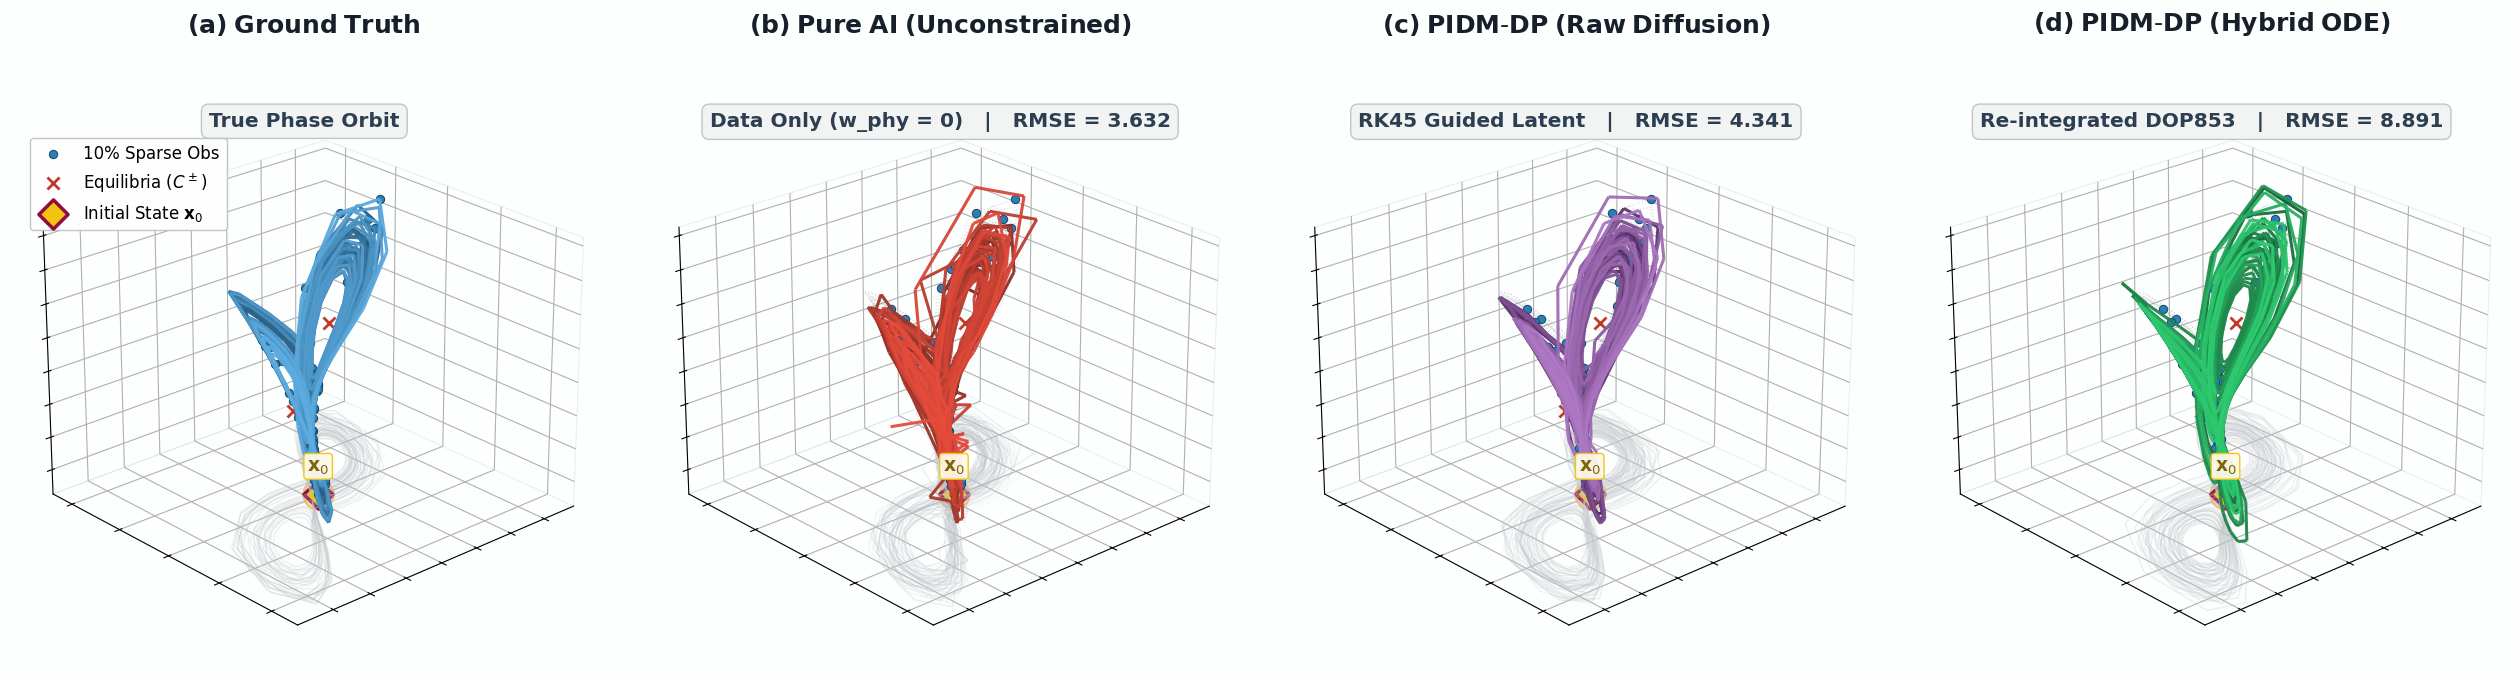

  ✓ Saved Figure 1 (3D Manifolds): /kaggle/working/figures/lorenz63/report_fig1_manifolds_lorenz.png


/tmp/ipykernel_57/3102583636.py:362: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig2.tight_layout()


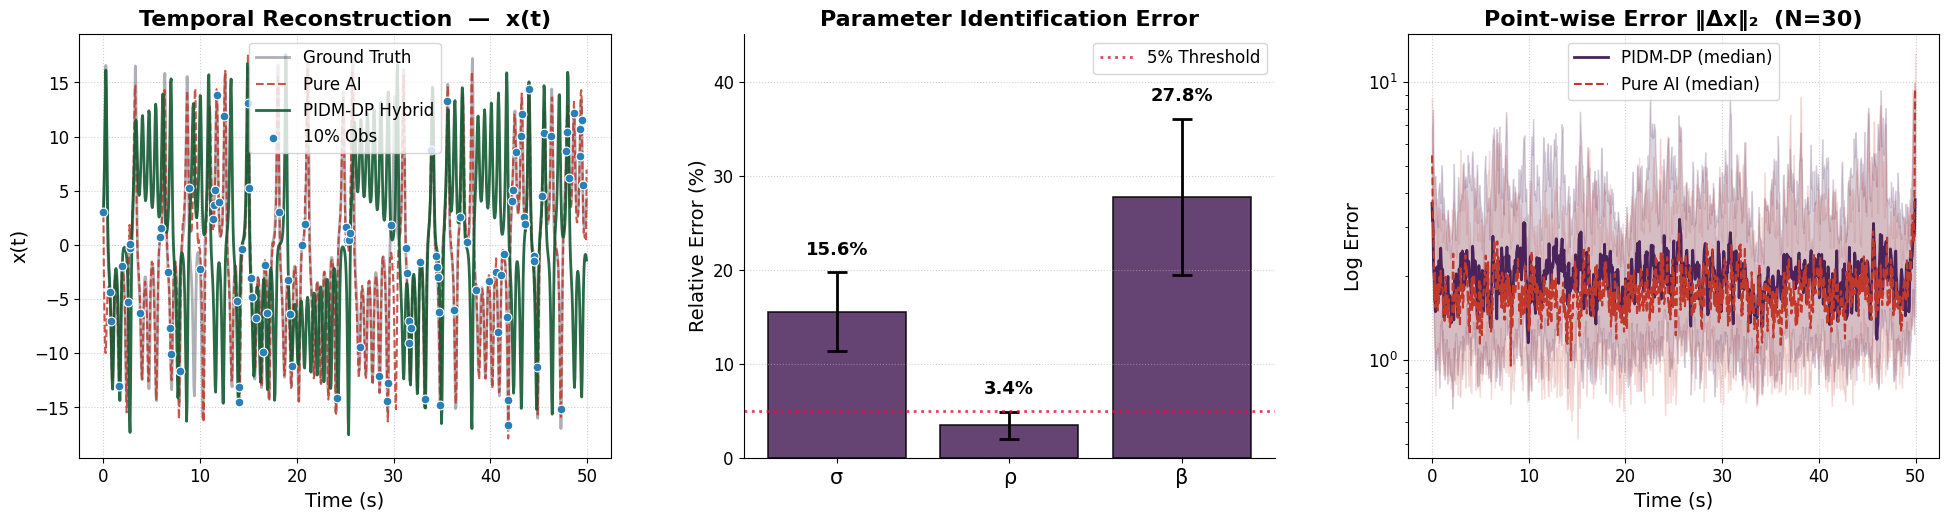

  ✓ Saved Figure 2 (Metrics): /kaggle/working/figures/lorenz63/report_fig2_metrics_lorenz.png


In [14]:



# =============================================================================
# MANIFOLD & METRICS SUITE (LORENZ-63) 
# Features: Large Subheadings & Prominent Glowing x0 Initial State Beacon
# =============================================================================

import os
import scipy.stats as st
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import torch
import numpy as np
from tqdm.auto import tqdm

# ── 1. Color Gradients & Colormap Builders ───────────────────────────────────
def make_custom_cmap(hex_start, hex_end, name):
    return LinearSegmentedColormap.from_list(name, [hex_start, hex_end], N=256)

CMAP_GT     = make_custom_cmap("#1B4F72", "#5DADE2", "gt_blues")     # Midnight Blue to Sky
CMAP_AI     = make_custom_cmap("#78281F", "#E74C3C", "ai_reds")      # Deep Crimson to Coral
CMAP_RAW    = make_custom_cmap("#4A235A", "#AF7AC5", "raw_purples")  # Plum to Lilac
CMAP_HYBRID = make_custom_cmap("#145A32", "#2ECC71", "hyb_greens")   # Forest to Emerald

# ── 2. Depth-Sorted Gradient 3D Trajectory ───────────────────────────────────
def plot_gradient_3d_trajectory(ax, x, y, z, cmap, lw=2.2, alpha=0.95, zorder=4):
    points = np.array([x, y, z]).T.reshape(-1, 1, 3)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    t_norm = np.linspace(0.0, 1.0, len(segments))
    colors = cmap(t_norm)
    colors[:, 3] = alpha
    lc = Line3DCollection(segments, colors=colors, linewidths=lw, zorder=zorder)
    ax.add_collection3d(lc)

# ── 3. Floor Projection Shadow ───────────────────────────────────────────────
def plot_floor_shadow(ax, x, y, z_floor, color="#BDC3C7", lw=0.9, alpha=0.25):
    z_proj = np.full_like(x, z_floor)
    points = np.array([x, y, z_proj]).T.reshape(-1, 1, 3)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = Line3DCollection(segments, colors=[color], linewidths=lw, alpha=alpha, zorder=1)
    ax.add_collection3d(lc)

# ── 4. Hybrid Re-integration (DOP853 with Recovered Parameters) ──────────────
def hybrid_reintegrate_lorenz(recon_phys, x_gt, dt):
    s_dim = CONFIG["lorenz"]["state_dim"]  # 3
    p_dim = CONFIG["lorenz"]["param_dim"]  # 3
    p_names = ["σ", "ρ", "β"]

    true_ic = x_gt[:s_dim, 0].tolist()
    true_params = [float(x_gt[s_dim + j, 0]) for j in range(p_dim)]

    early_end = min(300, recon_phys.shape[1])
    inferred_params = [
        float(np.median(recon_phys[s_dim + j, :early_end])) for j in range(p_dim)
    ]

    p_errs = {
        n: abs(i - t) / (abs(t) + 1e-9) * 100
        for n, i, t in zip(p_names, inferred_params, true_params)
    }

    ranges = CONFIG["lorenz"]["ranges"]
    safe_params = []
    for j, pv in enumerate(inferred_params):
        lo, hi = ranges[j]
        w = hi - lo
        safe_params.append(float(np.clip(pv, lo - 3 * w, hi + 3 * w)))

    fn_np = get_sys_fn("lorenz")
    t_span = (0.0, x_gt.shape[1] * dt)
    t_eval = np.linspace(0.0, x_gt.shape[1] * dt, x_gt.shape[1])

    try:
        sol = solve_ivp(
            fn_np, t_span, true_ic, args=tuple(safe_params),
            method="DOP853", t_eval=t_eval, rtol=1e-8, atol=1e-10
        )
        hybrid = (
            sol.y if (sol.success and np.isfinite(sol.y).all())
            else recon_phys[:s_dim]
        )
    except Exception:
        hybrid = recon_phys[:s_dim]

    return hybrid, inferred_params, true_params, p_errs

# ── 5. Master Simulation & Figure Generation Pipeline ────────────────────────
def run_and_plot_publication_manifolds(n_trials=20, save_dir=CONFIG["paths"]["figures"]):
    os.makedirs(save_dir, exist_ok=True)
    sys_name = "lorenz"
    s_dim = CONFIG[sys_name]["state_dim"]
    p_names = ["σ", "ρ", "β"]
    dt = CONFIG["data"]["dt"]

    model = models.get("full", models.get("lorenz"))
    prep  = preps.get("full", preps.get("lorenz"))
    diff  = diffs.get("full", diffs.get("lorenz"))
    model.eval().to(DEVICE)

    print(f"\n  [1/3] Generating {n_trials} chaotic test trajectories (dt={dt})...")
    set_seed(505)
    raw_samples = generate_chaotic_dataset(sys_name, n_samples=n_trials, n_points=1000, dt=dt, seed=505)

    pidm_rmse_list, ai_rmse_list, hybrid_rmse_list = [], [], []
    param_errors_all = {p: [] for p in p_names}
    true_params_all  = {p: [] for p in p_names}
    inf_params_all   = {p: [] for p in p_names}

    recon_trajs       = []
    recon_ai_trajs    = []
    hybrid_trajs      = []
    error_curves_pidm = []
    error_curves_ai   = []
    obs_idx_list      = []

    print(f"  [2/3] Running PIDM-DP & Pure AI guided inference...")
    for i in tqdm(range(n_trials), desc="Inference Progress"):
        x_gt = raw_samples[i]
        x_norm = prep.normalize(torch.tensor(raw_samples[i:i+1], dtype=torch.float32).to(DEVICE))
        mask, obs_idx = make_random_mask(x_norm.shape, CONFIG["data"]["obs_ratio"], DEVICE, s_dim)
        obs_idx_list.append(obs_idx)
        x_noisy = add_observation_noise(x_norm, mask, CONFIG["data"]["obs_noise"])

        # 1. PIDM-DP
        gfn_pidm = lambda x, t: stable_guidance(
            x, t, x_noisy, mask, model, diff, prep, sys_name, force_pure_ai=False
        )
        rec_pidm_n = guided_reconstruction(model, diff, prep, x_norm, mask, gfn_pidm)
        rec_pidm_p = prep.denormalize(rec_pidm_n).cpu().numpy()[0]

        # 2. Pure AI (w_phy = 0)
        gfn_ai = lambda x, t: stable_guidance(
            x, t, x_noisy, mask, model, diff, prep, sys_name, force_pure_ai=True
        )
        rec_ai_n = guided_reconstruction(model, diff, prep, x_norm, mask, gfn_ai)
        rec_ai_p = prep.denormalize(rec_ai_n).cpu().numpy()[0]

        # 3. Hybrid Re-integration
        hybrid, inf_p, true_p, p_errs = hybrid_reintegrate_lorenz(rec_pidm_p, x_gt, dt)

        recon_trajs.append(rec_pidm_p)
        recon_ai_trajs.append(rec_ai_p)
        hybrid_trajs.append(hybrid)

        gt_state = x_gt[:s_dim]
        pidm_rmse_list.append(trajectory_rmse(gt_state, rec_pidm_p[:s_dim]))
        ai_rmse_list.append(trajectory_rmse(gt_state, rec_ai_p[:s_dim]))
        hybrid_rmse_list.append(trajectory_rmse(gt_state, hybrid))

        error_curves_pidm.append(np.linalg.norm(rec_pidm_p[:s_dim] - gt_state, axis=0))
        error_curves_ai.append(np.linalg.norm(rec_ai_p[:s_dim] - gt_state, axis=0))

        for pn, pe, t_val, i_val in zip(p_names, p_errs.values(), true_p, inf_p):
            param_errors_all[pn].append(pe)
            true_params_all[pn].append(t_val)
            inf_params_all[pn].append(i_val)

    # ── [3/3] Render Figure 1: Publication 3D Manifolds ──────────────────────
    print("  [3/3] Rendering Publication Figures...")
    median_idx = int(np.argmin(np.abs(np.array(pidm_rmse_list) - np.median(pidm_rmse_list))))
    x_gt_med = raw_samples[median_idx]
    traj_ai = recon_ai_trajs[median_idx][:s_dim]
    traj_raw = recon_trajs[median_idx][:s_dim]
    traj_hyb = hybrid_trajs[median_idx]
    exact_obs_idx = obs_idx_list[median_idx]

    pad = 2.5
    xlim = (float(x_gt_med[0].min()) - pad, float(x_gt_med[0].max()) + pad)
    ylim = (float(x_gt_med[1].min()) - pad, float(x_gt_med[1].max()) + pad)
    zlim = (float(x_gt_med[2].min()) - pad, float(x_gt_med[2].max()) + pad)
    z_floor = zlim[0]

    # Classical Lorenz equilibria C+ and C-
    sigma_v, rho_v, beta_v = [float(np.mean(CONFIG["lorenz"]["ranges"][j])) for j in range(3)]
    c_star = np.sqrt(max(0.0, beta_v * (rho_v - 1.0)))
    c_plus  = np.array([ c_star,  c_star, rho_v - 1.0])
    c_minus = np.array([-c_star, -c_star, rho_v - 1.0])

    # Initial condition coordinates
    x0_coord = (float(x_gt_med[0, 0]), float(x_gt_med[1, 0]), float(x_gt_med[2, 0]))

    plt.rcParams["font.family"] = "sans-serif"
    fig1 = plt.figure(figsize=(26, 7.5), facecolor="#FDFEFE")
    gs1 = gridspec.GridSpec(1, 4, figure=fig1, wspace=0.08, left=0.02, right=0.98, top=0.86, bottom=0.05)

    panels = [
        (r"$\mathbf{(a)\;Ground\;Truth}$",                     x_gt_med[:s_dim], CMAP_GT,     None,                      "True Phase Orbit"),
        (r"$\mathbf{(b)\;Pure\;AI\;(Unconstrained)}$",          traj_ai,          CMAP_AI,     np.mean(ai_rmse_list),     "Data Only (w_phy = 0)"),
        (r"$\mathbf{(c)\;PIDM\text{-}DP\;(Raw\;Diffusion)}$",   traj_raw,         CMAP_RAW,    np.mean(pidm_rmse_list),   "RK45 Guided Latent"),
        (r"$\mathbf{(d)\;PIDM\text{-}DP\;(Hybrid\;ODE)}$",      traj_hyb,         CMAP_HYBRID, np.mean(hybrid_rmse_list), "Re-integrated DOP853")
    ]

    for col, (title, traj, cmap, rmse_val, subtitle) in enumerate(panels):
        ax = fig1.add_subplot(gs1[0, col], projection="3d")
        ax.set_facecolor((1, 1, 1, 0))

        # 1. Floor projection shadow
        plot_floor_shadow(ax, traj[0], traj[1], z_floor, color="#BDC3C7", lw=0.9, alpha=0.28)

        # 2. Ghost Ground Truth Trajectory on non-GT panels
        if col > 0:
            plot_floor_shadow(ax, x_gt_med[0], x_gt_med[1], z_floor, color="#D5D8DC", lw=0.7, alpha=0.18)
            ax.plot(x_gt_med[0], x_gt_med[1], x_gt_med[2], color="#7F8C8D", lw=0.9, alpha=0.25, zorder=2, ls=":")

        # 3. Dynamic Gradient Phase Trajectory
        plot_gradient_3d_trajectory(ax, traj[0], traj[1], traj[2], cmap=cmap, lw=2.2, alpha=0.95, zorder=4)

        # 4. 10% Observation points
        ax.scatter(
            x_gt_med[0, exact_obs_idx], x_gt_med[1, exact_obs_idx], x_gt_med[2, exact_obs_idx],
            color="#2980B9", s=36, edgecolors="#154360", linewidths=0.7,
            depthshade=False, zorder=10, label="10% Sparse Obs" if col == 0 else None
        )

        # 5. Equilibria C+ and C-
        ax.scatter(
            [c_plus[0], c_minus[0]], [c_plus[1], c_minus[1]], [c_plus[2], c_minus[2]],
            color="#C0392B", marker="x", s=75, linewidths=2.0, depthshade=False, zorder=12,
            label=r"Equilibria ($C^\pm$)" if col == 0 else None
        )

        # ── 6. HIGH-VISIBILITY INITIAL STATE x0 BEACON ───────────────────────
        # Halo glow layer (semi-transparent white)
        ax.scatter(
            [x0_coord[0]], [x0_coord[1]], [x0_coord[2]],
            color="#FFFFFF", edgecolors="#F39C12", marker="o", s=450, linewidths=2.0,
            alpha=0.60, depthshade=False, zorder=20
        )
        # Radiant gold diamond center with dark ruby border
        ax.scatter(
            [x0_coord[0]], [x0_coord[1]], [x0_coord[2]],
            color="#F1C40F", edgecolor="#900C3F", marker="D", s=220, linewidths=2.5,
            depthshade=False, zorder=25, label=r"Initial State $\mathbf{x}_0$" if col == 0 else None
        )
        # 3D Callout Text Label right above x0
        ax.text(
            x0_coord[0], x0_coord[1], x0_coord[2] + 2.8,
            r"$\mathbf{x}_0$",
            fontsize=13.5, fontweight="bold", color="#7D6608", zorder=30,
            ha="center", va="bottom",
            bbox=dict(boxstyle="round,pad=0.18", facecolor="#FEF9E7", edgecolor="#F1C40F", lw=1.0, alpha=0.95)
        )

        # ── Framing & Perspective ────────────────────────────────────────────
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_zlim(zlim)
        ax.set_box_aspect([1.0, 1.0, 0.78])

        for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
            pane.fill = False
            pane.set_edgecolor((0.85, 0.88, 0.90, 0.6))
            pane.set_linewidth(0.8)

        ax.grid(True, linestyle=":", color="#D0D3D4", alpha=0.5, linewidth=0.6)
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_zticklabels([])
        ax.view_init(elev=24, azim=48)

        # ── BIGGER TITLES & SUB-HEADINGS ─────────────────────────────────────
        rmse_badge = f"   |   RMSE = {rmse_val:.3f}" if rmse_val is not None else ""
        ax.set_title(f"{title}\n", fontsize=18, fontweight="bold", pad=16, color="#17202A")
        ax.text2D(
            0.5, 0.95, f"{subtitle}{rmse_badge}",
            transform=ax.transAxes, ha="center", va="top",
            fontsize=14.5, fontweight="semibold", color="#2C3E50",
            bbox=dict(boxstyle="round,pad=0.38", facecolor="#F2F4F4", edgecolor="#BDC3C7", lw=1.0, alpha=0.95)
        )

        if col == 0:
            leg = ax.legend(
                loc="upper left", bbox_to_anchor=(0.02, 0.92),
                fontsize=12.0, frameon=True, facecolor="#FFFFFF", edgecolor="#BDC3C7", framealpha=0.95
            )
            leg.get_frame().set_linewidth(1.0)

    path1_pdf = os.path.join(save_dir, "report_fig1_manifolds_lorenz.pdf")
    path1_png = os.path.join(save_dir, "report_fig1_manifolds_lorenz.png")
    fig1.savefig(path1_pdf, dpi=300, bbox_inches="tight")
    fig1.savefig(path1_png, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"  ✓ Saved Figure 1 (3D Manifolds): {path1_png}")

    # ── Render Figure 2: Quantitative Metrics ────────────────────────────────
    fig2 = plt.figure(figsize=(24, 5.5), facecolor="white")
    gs2 = gridspec.GridSpec(1, 3, figure=fig2, wspace=0.25)
    t_ax = np.arange(1000) * dt

    # 2A: Temporal Trace
    ax_ts = fig2.add_subplot(gs2[0, 0])
    ax_ts.plot(t_ax, x_gt_med[0], color="#1A1A2E", lw=2.0, alpha=0.35, label="Ground Truth")
    ax_ts.plot(t_ax, recon_ai_trajs[median_idx][0], color="#C0392B", lw=1.5, ls="--", alpha=0.85, label="Pure AI")
    ax_ts.plot(t_ax, hybrid_trajs[median_idx][0], color="#145A32", lw=2.0, alpha=0.90, label="PIDM-DP Hybrid")
    ax_ts.scatter(
        t_ax[exact_obs_idx], x_gt_med[0, exact_obs_idx],
        color="#2980B9", s=40, zorder=5, edgecolors="white", linewidths=0.8, label="10% Obs"
    )
    ax_ts.set_title("Temporal Reconstruction  —  x(t)", fontsize=16, fontweight="bold")
    ax_ts.set_xlabel("Time (s)", fontsize=14)
    ax_ts.set_ylabel("x(t)", fontsize=14)
    ax_ts.tick_params(labelsize=12)
    ax_ts.legend(fontsize=12)
    ax_ts.grid(True, ls=":", alpha=0.6)

    # 2B: Parameter Error
    ax_par = fig2.add_subplot(gs2[0, 1])
    mean_errs = [np.mean(param_errors_all[p]) for p in p_names]
    ci_errs = [
        (st.sem(param_errors_all[p]) * st.t.ppf(0.975, max(len(param_errors_all[p]) - 1, 1))
         if len(param_errors_all[p]) > 1 else 0.0)
        for p in p_names
    ]
    xpos = np.arange(len(p_names))
    bars = ax_par.bar(
        xpos, mean_errs, yerr=ci_errs, color="#4A235A", alpha=0.85, capsize=7,
        edgecolor="black", linewidth=1.2, error_kw={"lw": 2.0, "capthick": 2.0}
    )
    max_val = max([m + c for m, c in zip(mean_errs, ci_errs)]) if mean_errs else 5.0
    for bar, me, ce in zip(bars, mean_errs, ci_errs):
        ax_par.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height() + ce + max_val * 0.04,
            f"{me:.1f}%", ha="center", va="bottom", fontsize=13, fontweight="bold"
        )
    ax_par.set_xticks(xpos)
    ax_par.set_xticklabels(p_names, fontsize=15)
    ax_par.axhline(5, color="crimson", ls=":", lw=2.0, alpha=0.8, label="5% Threshold")
    ax_par.set_title("Parameter Identification Error", fontsize=16, fontweight="bold")
    ax_par.set_ylabel("Relative Error (%)", fontsize=14)
    ax_par.tick_params(axis="y", labelsize=12)
    ax_par.set_ylim(0, max_val * 1.25)
    ax_par.legend(fontsize=12)
    ax_par.grid(axis="y", ls=":", alpha=0.6)
    for sp in ["top", "right"]:
        ax_par.spines[sp].set_visible(False)

    # 2C: Semi-Log Error
    ax_err = fig2.add_subplot(gs2[0, 2])
    med_pidm = np.median(error_curves_pidm, axis=0)
    med_ai   = np.median(error_curves_ai, axis=0)
    p25_pidm = np.percentile(error_curves_pidm, 25, axis=0)
    p75_pidm = np.percentile(error_curves_pidm, 75, axis=0)
    p25_ai   = np.percentile(error_curves_ai, 25, axis=0)
    p75_ai   = np.percentile(error_curves_ai, 75, axis=0)
    eps = 1e-9

    ax_err.semilogy(t_ax, med_pidm + eps, color="#4A235A", lw=2.0, label="PIDM-DP (median)")
    ax_err.semilogy(t_ax, med_ai + eps, color="#C0392B", lw=1.5, ls="--", label="Pure AI (median)")
    ax_err.fill_between(t_ax, p25_pidm + eps, p75_pidm + eps, alpha=0.20, color="#4A235A")
    ax_err.fill_between(t_ax, p25_ai + eps, p75_ai + eps, alpha=0.15, color="#C0392B")
    ax_err.set_title(f"Point-wise Error ‖Δx‖₂  (N={n_trials})", fontsize=16, fontweight="bold")
    ax_err.set_xlabel("Time (s)", fontsize=14)
    ax_err.set_ylabel("Log Error", fontsize=14)
    ax_err.tick_params(labelsize=12)
    ax_err.legend(fontsize=12)
    ax_err.grid(True, ls=":", alpha=0.6)

    fig2.tight_layout()
    path2_pdf = os.path.join(save_dir, "report_fig2_metrics_lorenz.pdf")
    path2_png = os.path.join(save_dir, "report_fig2_metrics_lorenz.png")
    fig2.savefig(path2_pdf, dpi=300, bbox_inches="tight")
    fig2.savefig(path2_png, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"  ✓ Saved Figure 2 (Metrics): {path2_png}")

# ── Execute Directly ─────────────────────────────────────────────────────────
run_and_plot_publication_manifolds(n_trials=30)


## Summary of results

All numbers below are taken from the recorded outputs above.

| Setting | PIDM-DP RMSE | Data-only RMSE | EnKF RMSE |
|---|---|---|---|
| ID, N=30 | 4.16 ± 2.92 | 3.88 ± 2.60 | 2.25 ± 1.82 |
| OOD, N=30 | 2.31 ± 1.56 | 2.10 ± 1.45 | 1.16 ± 0.77 |
| Micro (~53k), N=15 | 11.82 ± 1.54 | 13.54 ± 1.60 | 1.87 ± 1.15 |

* PIDM-DP vs. data-only guidance is **not significantly different** at full scale (Wilcoxon p ≈ 0.09 ID, 0.08 OOD); it is significantly better only for the micro model (p ≈ 6e-5), where both are poor.
* The oracle-initialised EnKF is significantly better than both diffusion variants (p < 1e-5).
* ρ is recovered far better (MAPE 4.1 % ID) than σ (20.0 %) or β (20.3 %).
* The λ_phy sweep (Phase 5) and noise × sparsity grid (Phase 6) show gains of roughly 0.8–1.1×, i.e. no consistent benefit from the physics term in these settings.

These are honest limitations; see the repository README for discussion.